# Predicción de la duración de viajes en Ecobici con PySpark y MLlib

A01199004 Oswaldo Isaias Hernández Santes

Concentración de Inteligencia Artificial Avanzada para la Ciencia de Datos

Subcompetencia SMA0104C Uso, procesamiento y visualización de grandes volúmenes de datos

6 de noviembre de 2026

## Resumen

Se procesaron con PySpark en Google Colab 42.4 millones de viajes de Ecobici de 2024 y 2025 que pesan 2.48 GB en CSV, los datos se convirtieron a Parquet lo que redujo su peso al 23% e hizo las consultas 13 veces más rápidas y después de unirlos con el catálogo de estaciones y limpiarlos quedaron 40.6 millones de viajes.

Con ayuda de MLlib se entrenó una regresión lineal y un Random Forest con una muestra de 10 millones de viajes para predecir la duración de un viaje, el Random Forest tuvo el menor error con un MAE de 4.04 minutos y un R² de 0.592 y con los viajes de enero de 2026 que no vio durante el entrenamiento obtuvo un MAE de 3.99 minutos y un R² de 0.597.

Los resultados se presentan en un tablero de Tableau Public con tres dashboards que muestran las horas pico, las estaciones con más viajes, quién usa el sistema y el error del modelo para apoyar las decisiones del operador.

## Introducción

Ecobici es el sistema de bicicletas públicas de la Ciudad de México y opera desde 2010, los usuarios toman una bicicleta en una cicloestación y la dejan en otra y cada viaje queda registrado con la estación, la fecha y la hora de salida y de llegada, en 2024 el sistema registró más de 22 millones de viajes y con ese volumen ya no es práctico analizar los datos con herramientas que los cargan completos en la memoria de una sola computadora por eso se usa Spark que divide los datos en partes y las procesa en paralelo.

Saber cuánto va a durar un viaje le sirve al usuario para planear su trayecto y al operador del sistema porque la duración indica cuándo una bicicleta va a volver a estar disponible en la estación de destino.

El objetivo de este proyecto es procesar los viajes de Ecobici de 2024 y 2025 con PySpark, entrenar un modelo de regresión con MLlib que prediga la duración de un viaje a partir de la distancia, las estaciones, la hora, el día y la edad y el género del usuario, evaluarlo con los viajes de enero de 2026 que el modelo no vio durante el entrenamiento y construir un tablero en Tableau Public que apoye la toma de decisiones del operador.

## Dataset

Los datos son los registros de viajes de Ecobici que publica el Gobierno de la Ciudad de México en el sitio del sistema cada mes se publica en un archivo CSV con un viaje por fila.

Para el entrenamiento se usan los 24 meses de 2024 y 2025 y enero de 2026 se guarda aparte para las predicciones finales.

Página de los datos: https://ecobici.cdmx.gob.mx/datos-abiertos/

Cada viaje tiene las siguientes columnas.

| Columna | Descripción |
|---|---|
| Genero_Usuario | Género del usuario |
| Edad_Usuario | Edad del usuario en años |
| Bici | Número de la bicicleta |
| Ciclo_Estacion_Retiro | Número de la estación donde se tomó la bicicleta |
| Fecha_Retiro | Fecha en que se tomó la bicicleta |
| Hora_Retiro | Hora en que se tomó la bicicleta |
| Ciclo_EstacionArribo | Número de la estación donde se dejó la bicicleta |
| Fecha_Arribo | Fecha en que se dejó la bicicleta |
| Hora_Arribo | Hora en que se dejó la bicicleta |

Los viajes no traen la distancia ni la ubicación de las estaciones también por eso se usa el catálogo de cicloestaciones del Portal de Datos Abiertos de la Ciudad de México que tiene el número, la colonia, la alcaldía, la latitud y la longitud de cada estación.

Catálogo de cicloestaciones: https://datos.cdmx.gob.mx/dataset/cicloestaciones-ecobici-nuevo-sistema

Las columnas se tomaron de un archivo de 2024 y pueden cambiar un poco entre años, en la sección de carga se revisa el esquema de cada mes antes de unirlos.

## Entorno

Spark corre sobre Java es por eso que primero se revisa que Colab tenga Java instalado, después se instala PySpark 3.5.5 que es la librería para usar Spark desde Python y se fija la versión para que el notebook funcione igual cada vez que se corra.

Al instalar PySpark aparece un aviso de pip sobre el paquete dataproc-spark-connect que pide PySpark 4, ese paquete viene instalado en Colab para conectarse a Google Cloud y no se usa en este notebook por eso el aviso no afecta la ejecución.

In [ ]:
!java -version
!pip install -q pyspark==3.5.5

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [ ]:
import json
import os
import shutil
import time
import urllib.request
from functools import reduce
from pathlib import Path

import pandas as pd
import psutil
from pyspark.sql import DataFrame, SparkSession
from pyspark.sql import functions as F

In [ ]:
# Recursos de la máquina de Colab para saber cuántos datos se pueden procesar a la vez
print("Núcleos:", os.cpu_count())
print(f"RAM total: {psutil.virtual_memory().total / 1024**3:.1f} GB")
print(f"Disco libre: {shutil.disk_usage('/content').free / 1024**3:.1f} GB")

Núcleos: 2
RAM total: 12.7 GB
Disco libre: 106.7 GB


Spark corre en modo local que quiere decir que la máquina de Colab funciona como un solo nodo y cada núcleo procesa una parte de los datos al mismo tiempo, se le asigna a Spark el 60% de la RAM y el resto queda para Python y el sistema.

Las particiones de shuffle se bajan de 200 a cuatro por núcleo, el shuffle es el paso en el que Spark reparte los datos entre tareas para poder agrupar y las 200 particiones que trae por defecto están pensadas para un clúster grande, en una máquina con pocos núcleos solo crean muchas tareas pequeñas que agregan tiempo.

La zona horaria se fija en UTC para que Spark no mueva las horas, las fechas de Ecobici ya vienen en la hora local de la Ciudad de México.

In [ ]:
# Sesión de Spark en modo local con todos los núcleos y el 60% de la RAM
cores = os.cpu_count()
memory_gb = int(psutil.virtual_memory().total / 1024**3 * 0.6)
spark = (
    SparkSession.builder
    .appName("ecobici-duration")
    .master("local[*]")
    .config("spark.driver.memory", f"{memory_gb}g")
    .config("spark.sql.shuffle.partitions", cores * 4)
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
print("Spark", spark.version, "con", cores, "núcleos y", memory_gb, "GB de memoria")

Spark 3.5.5 con 2 núcleos y 7 GB de memoria


Se conecta Google Drive para guardar un respaldo de las salidas en la carpeta respaldo-notebook/ecobici, si Colab se desconecta durante el entrenamiento lo que ya terminó queda guardado, al correr esta celda Colab pide permiso para entrar a la cuenta de Drive y hay que aceptarlo con la misma cuenta donde está la carpeta.

In [ ]:
# Se conecta Google Drive y se busca la carpeta de respaldo dentro de Mi unidad
from google.colab import drive
drive.mount("/content/drive")
backup_root = next(Path("/content/drive/MyDrive").glob("*/modulo 6/respaldo-notebook"), None)

# Las salidas de este proyecto van en una subcarpeta para no mezclarse con las de otros notebooks
DRIVE_DIR = backup_root / "ecobici" if backup_root else None
if DRIVE_DIR:
    DRIVE_DIR.mkdir(exist_ok=True)
print("Respaldo en:", DRIVE_DIR if DRIVE_DIR else "no se encontró la carpeta, las salidas solo se guardan en Colab")

Mounted at /content/drive
Respaldo en: /content/drive/MyDrive/Concentración Inteligencia Artificial Avanzada para la Ciencia de Datos/modulo 6/respaldo-notebook/ecobici


## Salidas y figuras

Las tablas y las figuras que se generan en el notebook se guardan en /content/salidas con la misma estructura de carpetas del repositorio y cada archivo también se copia a la carpeta de respaldo en Drive.

Las figuras se numeran en el orden en que aparecen, debajo de cada una está su pie con el número y lo que muestra y después la interpretación de lo que se ve, los valores de cada barra se escriben en la gráfica para poder leerlos sin estimarlos con el eje.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# Carpeta de salidas con la misma estructura del repositorio y carpeta para los modelos
OUTPUT_DIR = Path("/content/salidas")
MODEL_DIR = Path("/content/modelos")

In [ ]:
def backup(path):
    ''' Copia un archivo o una carpeta de /content a la misma ruta dentro del respaldo en Drive '''

    if DRIVE_DIR is None:
        return

    # Las carpetas como los modelos de Spark se copian completas
    target = DRIVE_DIR / path.relative_to("/content")
    target.parent.mkdir(parents=True, exist_ok=True)
    if path.is_dir():
        shutil.copytree(path, target, dirs_exist_ok=True)
    else:
        shutil.copy(path, target)


def save_table(table, relative_path):
    ''' Guarda una tabla de pandas en CSV dentro de las salidas y la respalda en Drive '''

    path = OUTPUT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False)
    backup(path)
    print(f"Guardado {relative_path} con {len(table):,} filas")


def save_figure(figure, relative_path):
    ''' Guarda una gráfica en PNG dentro de las salidas y la respalda en Drive '''

    path = OUTPUT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    backup(path)

In [ ]:
# Estilo de las gráficas con fondo claro, texto oscuro y cuadrícula tenue
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#898781",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": "#0b0b0b",
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.axisbelow": True,
})
BLUE, ORANGE, GRAY, GREEN, RED = "#2a78d6", "#eb6834", "#898781", "#1d6b46", "#b8423a"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DAY_LABELS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MONTH_LABELS = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

## Descarga de los datos

Los archivos de Ecobici no siguen un patrón en su nombre ni en su carpeta por ejemplo enero de 2024 se llama ecobici_2024_enero.csv, marzo de 2024 se llama datos_abiertos_2024_03-1-1.csv y la carpeta corresponde al mes en que se subió el archivo y no al mes de los datos, por eso las ligas se copiaron una por una de la página de datos abiertos y no se arman con una fórmula.

Cada archivo se descarga primero con otro nombre y se renombra hasta que termina y si se corta la conexión no queda un archivo a medias que parezca completo y al volver a correr la celda se descarga de nuevo.

Los archivos que ya existen no se vuelven a descargar.

In [ ]:
# Ligas de cada mes copiadas de la página de datos abiertos de Ecobici
BASE_URL = "https://ecobici.cdmx.gob.mx/wp-content/uploads/"
TRAIN_FILES = {
    "2024-01": "2024/02/ecobici_2024_enero.csv",
    "2024-02": "2024/03/2024-02.csv",
    "2024-03": "2024/04/datos_abiertos_2024_03-1-1.csv",
    "2024-04": "2024/05/datos_abiertos_2024_04.csv",
    "2024-05": "2024/06/2024-05-1.csv",
    "2024-06": "2024/07/2024-06.csv",
    "2024-07": "2024/08/datos_abiertos_2024_07.csv",
    "2024-08": "2024/09/2024-08.csv",
    "2024-09": "2024/10/2024-09.csv",
    "2024-10": "2024/11/2024-10.csv",
    "2024-11": "2024/12/2024-11.csv",
    "2024-12": "2025/01/2024-12.csv",
    "2025-01": "2025/02/2025-01.csv",
    "2025-02": "2025/03/2025-02.csv",
    "2025-03": "2025/04/2025-03.csv",
    "2025-04": "2025/05/2025-04.csv",
    "2025-05": "2025/06/2025-05.csv",
    "2025-06": "2025/07/2025-06.csv",
    "2025-07": "2025/08/2025-07.csv",
    "2025-08": "2025/09/2025-08.csv",
    "2025-09": "2025/10/2025-09.csv",
    "2025-10": "2025/11/2025-10-1.csv",
    "2025-11": "2025/12/2025-11.csv",
    "2025-12": "2026/01/2025-12.csv",
}
PREDICT_MONTH = "2026-01"
PREDICT_FILE = "2026/02/2026-01.csv"

# Carpetas de trabajo dentro de Colab
DATA_DIR = Path("/content/data")
RAW_DIR = DATA_DIR / "crudo"
RAW_DIR.mkdir(parents=True, exist_ok=True)
train_months = list(TRAIN_FILES)

In [ ]:
def download(url, path):
    ''' Descarga un archivo si todavía no existe y regresa su peso en MB '''

    # Se descarga primero a un archivo temporal para no dejar archivos a medias si se corta la conexión
    if not path.exists():
        temporary = path.with_suffix(".part")
        request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request) as response, open(temporary, "wb") as file:
            shutil.copyfileobj(response, file)
        temporary.rename(path)

    return path.stat().st_size / 1024**2

In [ ]:
# Se descarga cada mes con un nombre uniforme y se guarda el peso de cada archivo
start = time.time()
sizes = {}
files = {**TRAIN_FILES, PREDICT_MONTH: PREDICT_FILE}
for month, file in files.items():
    sizes[month] = download(BASE_URL + file, RAW_DIR / f"ecobici_{month}.csv")
    print(f"{month}: {sizes[month]:.1f} MB")

train_gb = sum(sizes[month] for month in train_months) / 1024
print(f"\nEntrenamiento: {train_gb:.2f} GB en {len(train_months)} archivos")
print(f"Predicciones {PREDICT_MONTH}: {sizes[PREDICT_MONTH]:.1f} MB")
print(f"Tiempo de descarga: {time.time() - start:.0f} s")

# El dataset debe pesar más de 1.1 GB y si no llega se agregan los meses de 2023
if train_gb < 1.1:
    print("El periodo de entrenamiento pesa menos de 1.1 GB, hay que agregar 2023")

2024-01: 91.2 MB
2024-02: 99.5 MB
2024-03: 107.1 MB
2024-04: 114.8 MB
2024-05: 120.2 MB
2024-06: 110.8 MB
2024-07: 106.9 MB
2024-08: 141.3 MB
2024-09: 138.4 MB
2024-10: 120.3 MB
2024-11: 113.7 MB
2024-12: 98.3 MB
2025-01: 105.8 MB
2025-02: 102.1 MB
2025-03: 107.2 MB
2025-04: 101.1 MB
2025-05: 104.0 MB
2025-06: 92.3 MB
2025-07: 97.3 MB
2025-08: 94.2 MB
2025-09: 92.8 MB
2025-10: 102.6 MB
2025-11: 93.6 MB
2025-12: 84.4 MB
2026-01: 89.1 MB

Entrenamiento: 2.48 GB en 24 archivos
Predicciones 2026-01: 89.1 MB
Tiempo de descarga: 34 s


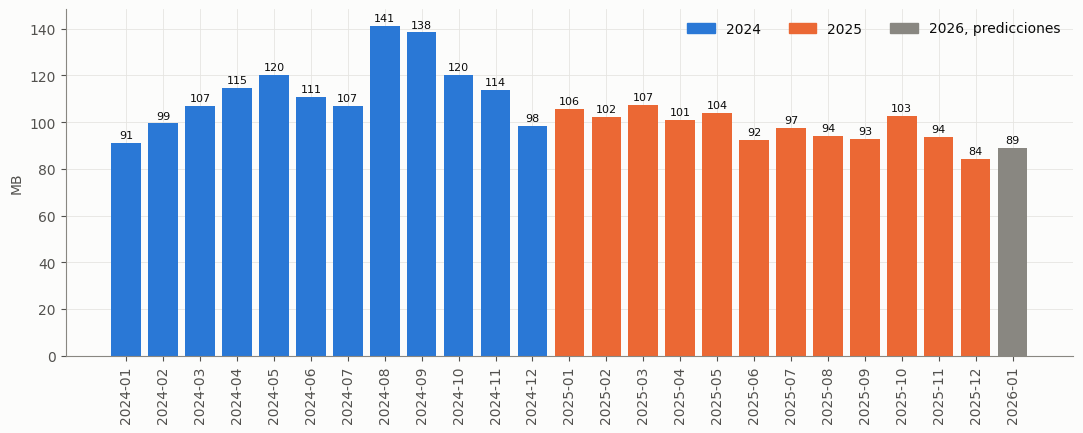

In [ ]:
# Figura 1, peso de cada archivo con un color por año
months = list(sizes)
colors = [BLUE if month.startswith("2024") else ORANGE if month.startswith("2025") else GRAY for month in months]
figure, ax = plt.subplots(figsize=(13, 4.5))
bars = ax.bar(range(len(months)), [sizes[month] for month in months], color=colors)
ax.bar_label(bars, labels=[f"{sizes[month]:.0f}" for month in months], padding=2, fontsize=8)
ax.set_xticks(range(len(months)))
ax.set_xticklabels(months, rotation=90)
ax.set_ylabel("MB")
ax.legend(handles=[Patch(color=BLUE, label="2024"), Patch(color=ORANGE, label="2025"), Patch(color=GRAY, label="2026, predicciones")], frameon=False, ncol=3)
save_figure(figure, "results/graficas/figura_01_peso_por_mes.png")
plt.show()

Figura 1. Peso en MB de cada archivo CSV, 2024 en azul, 2025 en naranja y enero de 2026 en gris.

Los 24 archivos de entrenamiento suman 2.48 GB, 2024 pesa 1.36 GB y 2025 pesa 1.18 GB, el archivo más pesado es agosto de 2024 con 141 MB y el más ligero es diciembre de 2025 con 84 MB.

Cada mes pesa alrededor de 100 MB es por eso que aunque se usara un solo año ya se pasaría de 1.1 GB.

El catálogo de cicloestaciones se descarga con la API del Portal de Datos Abiertos de la Ciudad de México que regresa los datos en formato JSON, el archivo CSV del portal viene con la codificación Latin-1 y la ñ de nombres como Niños Héroes se lee mal si se abre como UTF-8, la API regresa el texto correcto y así se evita ese problema.

Al ejecutar este notebook el 14 de noviembre de 2026 la API no respondió desde Colab aunque sí respondía desde un navegador en México, por eso se guardó la respuesta de la API en la carpeta de respaldo de Drive y si la consulta falla el notebook lee esa copia, así el notebook no depende de que el portal acepte conexiones desde los servidores de Colab.

El archivo trae filas vacías que se quitan y se guarda en CSV para leerlo después con Spark.

In [ ]:
# Consulta a la API del portal con un límite mayor al número de filas del catálogo
STATIONS_URL = "https://datos.cdmx.gob.mx/api/action/datastore_search?resource_id=5fbacfcc-f677-406c-9356-6ced541240fe&limit=5000"
try:
    request = urllib.request.Request(STATIONS_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=60) as response:
        result = json.load(response)["result"]
    print("Catálogo descargado de la API")

# Si el portal no responde desde Colab se lee la respuesta de la API guardada en Drive
except Exception as error:
    print("La API no respondió desde Colab:", error)
    with open(DRIVE_DIR / "cicloestaciones_api.json", encoding="utf-8") as file:
        result = json.load(file)["result"]
    print("Catálogo leído de la copia de la API guardada en Drive")
print("Filas en el catálogo:", result["total"])

# Se quitan las filas sin número de estación y se guarda el catálogo
stations_table = pd.DataFrame(result["records"]).drop(columns="_id")
stations_table = stations_table[stations_table["num_cicloe"].astype(str).str.strip() != ""]
stations_table.to_csv(DATA_DIR / "cicloestaciones.csv", index=False)
print("Estaciones:", len(stations_table))
stations_table.head()

La API no respondió desde Colab: <urlopen error [Errno 104] Connection reset by peer>
Catálogo leído de la copia de la API guardada en Drive
Filas en el catálogo: 677
Estaciones: 677


,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.36473,-99.174447,Arroyo,Instalada
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada


## Revisión del esquema

Los archivos de Ecobici los publican distintas personas a lo largo de los años y los nombres de las columnas o el formato de las fechas pueden cambiar entre meses y si se leen todos juntos sin revisarlos Spark puede unir columnas que no corresponden o dejar fechas vacías.

Cada mes se lee con Spark sin convertir los tipos y todas las columnas quedan como texto así se ve cómo viene cada valor en el archivo original.

Para cada mes se imprime el número de viajes, las columnas y el primer viaje como ejemplo.

In [ ]:
# Se revisan las filas, las columnas y un viaje de ejemplo de cada mes
start = time.time()
raw_counts = {}
previous_columns = None
for month in train_months + [PREDICT_MONTH]:
    df = spark.read.csv(str(RAW_DIR / f"ecobici_{month}.csv"), header=True)
    raw_counts[month] = df.count()
    print(f"{month}: {raw_counts[month]:,} viajes, {len(df.columns)} columnas")

    # Las columnas solo se imprimen cuando cambian respecto al mes anterior
    if df.columns != previous_columns:
        print("  columnas:", df.columns)
        previous_columns = df.columns
    print("  ejemplo:", list(df.first().asDict().values()))

print(f"\nViajes de entrenamiento: {sum(raw_counts[month] for month in train_months):,}")
print(f"Revisión en {time.time() - start:.0f} s")

2024-01: 1,558,100 viajes, 9 columnas
  columnas: ['Genero_Usuario', 'Edad_Usuario', 'Bici', 'Ciclo_Estacion_Retiro', 'Fecha_Retiro', 'Hora_Retiro', 'Ciclo_EstacionArribo', 'Fecha Arribo', 'Hora_Arribo']
  ejemplo: ['M', '48', '3371879', '113', '31/12/2023', '23:21:52', '659', '01/01/2024', '00:00:02']
2024-02: 1,699,409 viajes, 9 columnas
  ejemplo: ['F', '24', '8293276', '126', '31/01/2024', '23:34:37', '547', '01/02/2024', '00:00:03']
2024-03: 1,829,763 viajes, 9 columnas
  ejemplo: ['M', '33', '4044731', '254', '29/02/2024', '23:45:26', '546', '01/03/2024', '00:00:00']
2024-04: 1,961,633 viajes, 9 columnas
  columnas: ['Genero_Usuario', 'Edad_Usuario', 'Bici', 'Ciclo_Estacion_Retiro', 'Fecha_Retiro', 'Hora_Retiro', 'Ciclo_EstacionArribo', 'Fecha_Arribo', 'Hora_Arribo']
  ejemplo: ['M', '45', '2578060', '304', '31/03/2024', '23:25:50', '117', '01/04/2024', '00:00:04']
2024-05: 2,053,563 viajes, 9 columnas
  columnas: ['Genero_Usuario', 'Edad_Usuario', 'Bici', 'Ciclo_Estacion_Retiro'

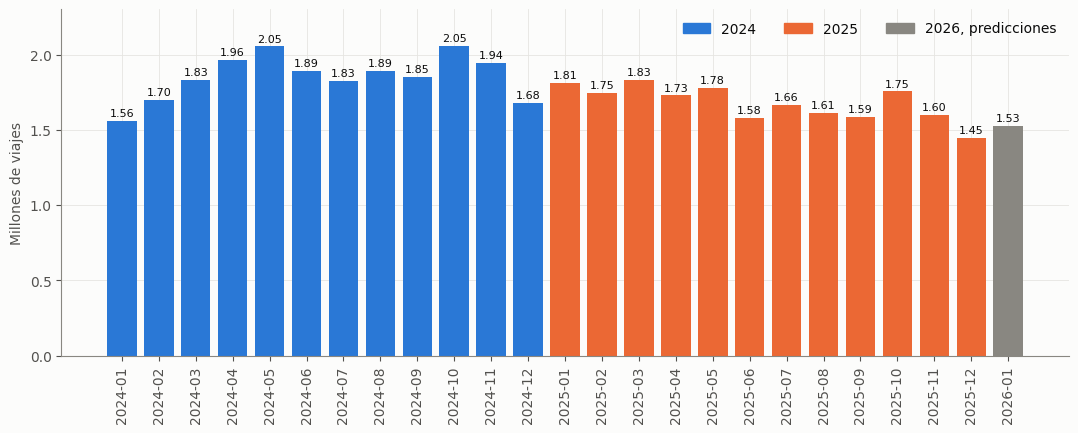

In [ ]:
# Figura 2, millones de viajes de cada mes en los archivos originales
months = train_months + [PREDICT_MONTH]
colors = [BLUE if month.startswith("2024") else ORANGE if month.startswith("2025") else GRAY for month in months]
values = [raw_counts[month] / 1e6 for month in months]
figure, ax = plt.subplots(figsize=(13, 4.5))
bars = ax.bar(range(len(months)), values, color=colors)
ax.bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=2, fontsize=8)
ax.set_xticks(range(len(months)))
ax.set_xticklabels(months, rotation=90)
ax.set_ylabel("Millones de viajes")
ax.set_ylim(0, max(values) * 1.12)
ax.legend(handles=[Patch(color=BLUE, label="2024"), Patch(color=ORANGE, label="2025"), Patch(color=GRAY, label="2026, predicciones")], frameon=False, ncol=3)
save_figure(figure, "results/graficas/figura_02_viajes_por_mes_originales.png")
plt.show()

Figura 2. Millones de viajes en cada archivo antes de la limpieza.

En 2024 hubo 22.2 millones de viajes y en 2025 hubo 20.1 millones, es decir 9.5% menos, los meses con más viajes fueron octubre y mayo de 2024 con 2.05 millones cada uno y el de menos viajes fue diciembre de 2025 con 1.45 millones. Entre el mes más bajo y el más alto hay 42% de diferencia, esto muestra que la demanda cambia según la temporada y más adelante se analiza con los datos limpios en la Figura 12.

Al comparar con la Figura 1 se ve que el peso de un archivo no depende solo de cuántos viajes tiene, agosto de 2024 es el archivo más pesado con 141 MB y 1.89 millones de viajes mientras que octubre de 2024 tiene 2.05 millones de viajes en 120 MB, esto indica que el formato del texto cambia entre archivos y es una razón más para revisar el esquema de cada mes antes de unirlos.

## Carga de los datos

La revisión mostró que los 25 archivos tienen las mismas 9 columnas en el mismo orden pero la columna de la fecha de llegada se llama `Fecha Arribo` con espacio en algunos meses de 2024 y `Fecha_Arribo` con guion bajo en los demás, si se unieran por nombre Spark crearía dos columnas distintas y la mitad de los viajes quedarían sin fecha de llegada, como el orden sí es el mismo las columnas se renombran por posición con nombres en inglés iguales para todos los meses.

La fecha y la hora vienen en columnas separadas con el formato 31/12/2023 y 23:21:52 se unen en un solo valor de fecha y hora y los viajes con una fecha que no se pueda leer quedan vacíos para quitarlos en la limpieza.

Los números de estación vienen con ceros a la izquierda como 007 y en el catálogo vienen sin ellos como 7, se quitan los ceros del inicio para que coincidan.

Algunas estaciones son dobles y vienen como 107-108 tanto en los viajes como en el catálogo, por eso se dejan igual.

La columna Bici no se usa porque es el número de la bicicleta y no dice nada sobre el viaje, si se usara el modelo podría aprender a reconocer bicicletas en lugar de aprender de la distancia y la hora.

In [ ]:
# Nombres uniformes para las 9 columnas en el orden en que vienen en todos los archivos
RAW_COLUMNS = ["gender", "age", "bike", "pickup_station", "pickup_date", "pickup_time", "dropoff_station", "dropoff_date", "dropoff_time"]

# Si una fecha no se puede leer queda vacía en lugar de detener el notebook
spark.conf.set("spark.sql.legacy.timeParserPolicy", "CORRECTED")

In [ ]:
def normalize_station(column):
    ''' Quita espacios y ceros a la izquierda del número de estación '''

    return F.regexp_replace(F.trim(F.col(column)), "^0+", "")


def to_datetime(date_column, time_column):
    ''' Une la fecha y la hora en un solo valor de fecha y hora '''

    # Las letras sencillas aceptan valores con o sin cero a la izquierda como 1/2/2024 o 01/02/2024
    return F.to_timestamp(F.concat_ws(" ", F.trim(F.col(date_column)), F.trim(F.col(time_column))), "d/M/yyyy H:m:s")


def load_month(month):
    ''' Lee un mes, renombra las columnas por posición y convierte cada una a su tipo '''

    df = spark.read.csv(str(RAW_DIR / f"ecobici_{month}.csv"), header=True).toDF(*RAW_COLUMNS)

    return df.select(
        F.upper(F.trim("gender")).alias("gender"),
        F.col("age").cast("double").cast("int").alias("age"),
        normalize_station("pickup_station").alias("pickup_station"),
        normalize_station("dropoff_station").alias("dropoff_station"),
        to_datetime("pickup_date", "pickup_time").alias("pickup"),
        to_datetime("dropoff_date", "dropoff_time").alias("dropoff"),
        F.lit(month).alias("file_month"),
    )

Los CSV se convierten a Parquet una sola vez y el resto del notebook lee el Parquet.

Parquet es un formato que guarda los datos por columnas con su tipo y comprimidos, esto permite leer solo las columnas que se necesitan y ocupa menos espacio en disco y Spark no tiene que volver a convertir el texto a números y fechas cada vez que lee los datos.

Los datos se guardan particionados por el mes del archivo, Spark crea una carpeta por mes y cuando una consulta necesita un solo mes solo abre esa carpeta.

In [ ]:
# Carpetas de los datos en Parquet
PARQUET_DIR = DATA_DIR / "parquet"

# Se unen los 24 meses de entrenamiento y se guardan en Parquet particionado por mes
start = time.time()
trips = reduce(DataFrame.unionByName, [load_month(month) for month in train_months])
trips.write.mode("overwrite").partitionBy("file_month").parquet(str(PARQUET_DIR / "entrenamiento"))
print(f"Conversión del entrenamiento a Parquet en {time.time() - start:.0f} s")

# El mes de las predicciones se convierte igual pero se guarda aparte
start = time.time()
load_month(PREDICT_MONTH).write.mode("overwrite").parquet(str(PARQUET_DIR / "prediccion"))
print(f"Conversión de {PREDICT_MONTH} a Parquet en {time.time() - start:.0f} s")

Conversión del entrenamiento a Parquet en 418 s
Conversión de 2026-01 a Parquet en 14 s


Para medir la diferencia entre los dos formatos se compara el peso en disco y el tiempo de una misma consulta, la consulta cuenta cuántos viajes salieron de cada estación y ordena las estaciones de la que tiene más viajes a la que tiene menos.

In [ ]:
def folder_size_gb(folder):
    ''' Suma el peso de todos los archivos de una carpeta en GB '''

    return sum(path.stat().st_size for path in folder.rglob("*") if path.is_file()) / 1024**3


def top_stations(df):
    ''' Cuenta los viajes por estación de salida y ordena de mayor a menor '''

    return df.groupBy("pickup_station").count().orderBy(F.desc("count")).collect()

In [ ]:
# Peso de los datos de entrenamiento en cada formato
parquet_gb = folder_size_gb(PARQUET_DIR / "entrenamiento")
print(f"CSV: {train_gb:.2f} GB")
print(f"Parquet: {parquet_gb:.2f} GB, el {parquet_gb / train_gb * 100:.0f}% del CSV")

# Tiempo de la misma consulta leyendo los CSV y leyendo el Parquet
start = time.time()
top_stations(reduce(DataFrame.unionByName, [load_month(month) for month in train_months]))
csv_seconds = time.time() - start

start = time.time()
train_raw = spark.read.parquet(str(PARQUET_DIR / "entrenamiento"))
top_stations(train_raw)
parquet_seconds = time.time() - start
print(f"\nConsulta con CSV: {csv_seconds:.1f} s")
print(f"Consulta con Parquet: {parquet_seconds:.1f} s, {csv_seconds / parquet_seconds:.1f} veces más rápida")

CSV: 2.48 GB
Parquet: 0.56 GB, el 23% del CSV

Consulta con CSV: 115.2 s
Consulta con Parquet: 8.6 s, 13.4 veces más rápida


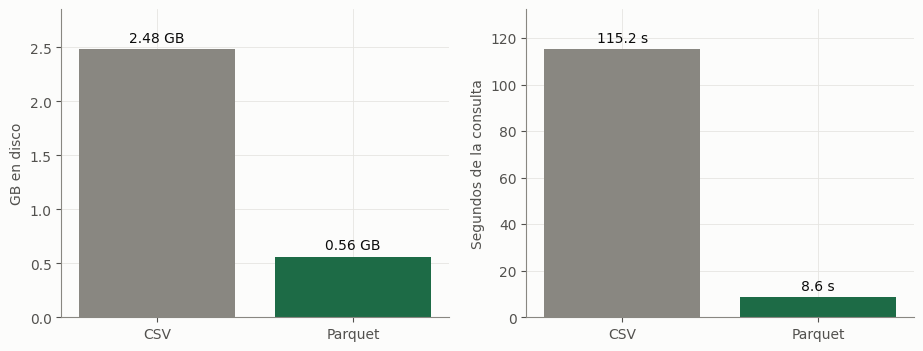

In [ ]:
# Figura 3, peso en disco y tiempo de la misma consulta en cada formato
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bars = ax1.bar(["CSV", "Parquet"], [train_gb, parquet_gb], color=[GRAY, GREEN])
ax1.bar_label(bars, labels=[f"{train_gb:.2f} GB", f"{parquet_gb:.2f} GB"], padding=3)
ax1.set_ylabel("GB en disco")
ax1.set_ylim(0, train_gb * 1.15)
bars = ax2.bar(["CSV", "Parquet"], [csv_seconds, parquet_seconds], color=[GRAY, GREEN])
ax2.bar_label(bars, labels=[f"{csv_seconds:.1f} s", f"{parquet_seconds:.1f} s"], padding=3)
ax2.set_ylabel("Segundos de la consulta")
ax2.set_ylim(0, csv_seconds * 1.15)
save_figure(figure, "results/graficas/figura_03_csv_contra_parquet.png")
plt.show()

Figura 3. Peso en disco de los datos de entrenamiento y tiempo de la misma consulta con CSV y con Parquet.

Parquet ocupa 0.56 GB que es el 23% de los 2.48 GB del CSV y la consulta tardó 8.6 segundos contra 115.2 que es 13.4 veces menos.

La consulta solo usa la columna de la estación de salida, con Parquet Spark lee solo esa columna y ya viene con su tipo mientras que con CSV tiene que leer las nueve columnas de los 24 archivos y convertir el texto en cada lectura.

La conversión tardó 260 segundos y cada consulta ahorra unos 65 segundos, por eso el tiempo de la conversión se recupera después de unas cuatro consultas y el resto del notebook consulta los datos muchas más veces.

Antes de definir las reglas de limpieza se revisan los valores de género y de edad y se comprueba cómo están agrupados los viajes en cada archivo, el primer viaje de cada mes en la revisión del esquema salió el último día del mes anterior y llegó el día 1, esto indica que cada archivo agrupa los viajes por la fecha de llegada y no por la de salida.

In [ ]:
# Valores de género ordenados del más común al menos común
train_raw.groupBy("gender").count().orderBy(F.desc("count")).show()

# Resumen de la edad con el conteo, el promedio, la desviación estándar, el mínimo y el máximo
train_raw.select("age").describe().show()

+------+--------+
|gender|   count|
+------+--------+
|     M|29092422|
|     F|11993090|
|     O|  816525|
|     ?|  475613|
|  NULL|     119|
+------+--------+

+-------+------------------+
|summary|               age|
+-------+------------------+
|  count|          42375981|
|   mean|33.910552395235406|
| stddev| 9.738365693133604|
|    min|                16|
|    max|               160|
+-------+------------------+



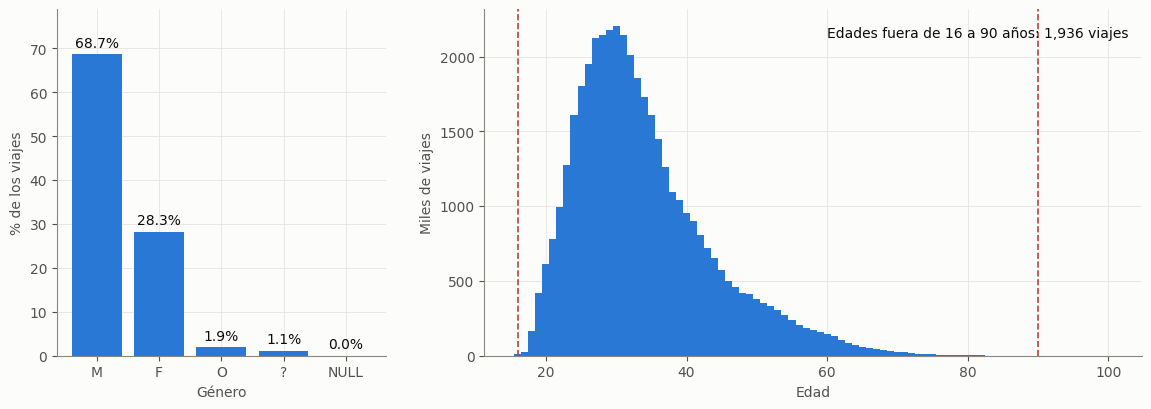

In [ ]:
# Viajes por género y por edad antes de la limpieza
gender_counts = train_raw.groupBy("gender").count().orderBy(F.desc("count")).toPandas()
age_counts = train_raw.groupBy("age").count().orderBy("age").toPandas().dropna()

# Figura 4, porcentaje de viajes por género y miles de viajes por edad con los límites de la limpieza
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
percent = gender_counts["count"] / gender_counts["count"].sum() * 100
bars = ax1.bar(gender_counts["gender"].fillna("vacío"), percent, color=BLUE)
ax1.bar_label(bars, labels=[f"{value:.1f}%" for value in percent], padding=3)
ax1.set_xlabel("Género")
ax1.set_ylabel("% de los viajes")
ax1.set_ylim(0, percent.max() * 1.15)
shown = age_counts[age_counts["age"] <= 100]
ax2.bar(shown["age"], shown["count"] / 1e3, color=BLUE, width=1)
ax2.axvline(16, color=RED, linestyle="--", linewidth=1.2)
ax2.axvline(90, color=RED, linestyle="--", linewidth=1.2)
outside = age_counts[(age_counts["age"] < 16) | (age_counts["age"] > 90)]["count"].sum()
ax2.text(0.98, 0.95, f"Edades fuera de 16 a 90 años: {outside:,} viajes", transform=ax2.transAxes, ha="right", va="top")
ax2.set_xlabel("Edad")
ax2.set_ylabel("Miles de viajes")
save_figure(figure, "results/graficas/figura_04_genero_y_edad.png")
plt.show()

Figura 4. Porcentaje de viajes por género y miles de viajes por edad antes de la limpieza, las líneas punteadas marcan los límites de 16 y 90 años que se usan en la limpieza y las edades mayores a 100 años no se dibujan porque son pocas.

El 68.7% de los viajes los hacen hombres y el 28.3% mujeres, los valores O y ? suman el 3% y los vacíos son solo 119 viajes.

El ? no se quita porque la duración de un viaje no depende de que el usuario haya dado su género y quitar esos viajes reduciría los datos sin mejorar el modelo.

La edad va de 16 a 160 años con un promedio de 33.9, la mayoría de los viajes se concentran entre los 20 y los 45 años y las edades mayores a 90 son errores de captura que se ven como barras casi vacías a la derecha de la línea, por eso el límite de 90 años quita valores imposibles como 160 sin quitar datos reales.

In [ ]:
# Viajes cuya salida o cuya llegada no está en el mes del archivo
month_check = train_raw.select(
    F.count("*").alias("viajes"),
    F.sum((F.date_format("pickup", "yyyy-MM") != F.col("file_month")).cast("int")).alias("salida_fuera_del_mes"),
    F.sum((F.date_format("dropoff", "yyyy-MM") != F.col("file_month")).cast("int")).alias("llegada_fuera_del_mes"),
)
month_check.show()

+--------+--------------------+---------------------+
|  viajes|salida_fuera_del_mes|llegada_fuera_del_mes|
+--------+--------------------+---------------------+
|42377769|                4194|                    0|
+--------+--------------------+---------------------+



## Unión con el catálogo de estaciones

Los viajes solo traen el número de la estación de salida y de llegada para saber dónde está cada una se unen con el catálogo que tiene su colonia, su alcaldía, su latitud y su longitud, el catálogo tiene 677 filas y se manda completo a cada tarea con broadcast así Spark no tiene que reacomodar los 42 millones de viajes para unirlos.

La unión es de tipo left que quiere decir que los viajes donde la estación no está en el catálogo se conservan con la ubicación vacía así se puede medir cuántos son antes de quitarlos en la limpieza, el catálogo es el actual y las estaciones que se retiraron o cambiaron de número entre 2024 y 2025 pueden no estar en él.

Con la latitud y la longitud de las dos estaciones se calcula la distancia del viaje con la fórmula del haversine que da la distancia en línea recta sobre la superficie de la Tierra en kilómetros.

La distancia real que recorre el ciclista es mayor porque sigue las calles, pero la distancia en línea recta crece igual que la real y sirve para comparar viajes cortos y largos.

In [ ]:
# Catálogo con el número de estación sin ceros a la izquierda y las coordenadas como números
stations = (
    spark.read.csv(str(DATA_DIR / "cicloestaciones.csv"), header=True)
    .select(
        F.regexp_replace(F.trim("num_cicloe"), "^0+", "").alias("station"),
        F.col("colonia"),
        F.col("alcaldia"),
        F.col("latitud").cast("double").alias("lat"),
        F.col("longitud").cast("double").alias("lon"),
    )
)
pickup_stations = stations.select([F.col(column).alias(f"pickup_{column}") for column in stations.columns])
dropoff_stations = stations.select([F.col(column).alias(f"dropoff_{column}") for column in stations.columns])
print("Estaciones en el catálogo:", stations.count())
stations.show(5)

Estaciones en el catálogo: 677
+-------+-------+-------------+---------+----------+
|station|colonia|     alcaldia|      lat|       lon|
+-------+-------+-------------+---------+----------+
|    423|Acacias|Benito Juarez|19.367816|-99.175269|
|    437|Acacias|Benito Juarez|19.364916|-99.175985|
|    438|Acacias|Benito Juarez| 19.36473|-99.174447|
|    439|Acacias|Benito Juarez|19.362037|-99.172683|
|    440|Acacias|Benito Juarez|19.361699|-99.171387|
+-------+-------+-------------+---------+----------+
only showing top 5 rows



In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    ''' Calcula la distancia en línea recta entre dos puntos de la Tierra en kilómetros '''

    # Las diferencias de latitud y longitud se convierten de grados a radianes
    dlat = F.radians(F.col(lat2) - F.col(lat1))
    dlon = F.radians(F.col(lon2) - F.col(lon1))
    a = F.sin(dlat / 2) ** 2 + F.cos(F.radians(F.col(lat1))) * F.cos(F.radians(F.col(lat2))) * F.sin(dlon / 2) ** 2

    # 6371 es el radio promedio de la Tierra en kilómetros
    return 2 * 6371 * F.asin(F.sqrt(a))


def add_stations(df):
    ''' Agrega la colonia, la alcaldía y las coordenadas de las dos estaciones y la distancia del viaje '''

    df = (
        df.join(F.broadcast(pickup_stations), "pickup_station", "left")
        .join(F.broadcast(dropoff_stations), "dropoff_station", "left")
    )

    return df.withColumn("distance_km", haversine_km("pickup_lat", "pickup_lon", "dropoff_lat", "dropoff_lon"))

In [ ]:
# Viajes cuya estación de salida o de llegada no está en el catálogo
start = time.time()
train_stations = add_stations(train_raw)
match = train_stations.select(
    F.count("*").alias("viajes"),
    F.sum(F.col("pickup_lat").isNull().cast("int")).alias("salida_sin_catalogo"),
    F.sum(F.col("dropoff_lat").isNull().cast("int")).alias("llegada_sin_catalogo"),
).collect()[0]
print(f"Revisión en {time.time() - start:.1f} s")
print(f"Salida sin catálogo: {match['salida_sin_catalogo']:,} viajes, el {match['salida_sin_catalogo'] / match['viajes'] * 100:.2f}%")
print(f"Llegada sin catálogo: {match['llegada_sin_catalogo']:,} viajes, el {match['llegada_sin_catalogo'] / match['viajes'] * 100:.2f}%")

# Las 10 estaciones de salida con más viajes que no están en el catálogo
(
    train_stations.filter(F.col("pickup_lat").isNull())
    .groupBy("pickup_station")
    .count()
    .orderBy(F.desc("count"))
    .show(10)
)

Revisión en 17.1 s
Salida sin catálogo: 474 viajes, el 0.00%
Llegada sin catálogo: 1,372 viajes, el 0.00%
+--------------------+-----+
|      pickup_station|count|
+--------------------+-----+
|Temporal - 2da Se...|  399|
|                1000|   74|
|                1002|    1|
+--------------------+-----+



In [ ]:
# Resumen de la distancia de los viajes que sí encontraron sus dos estaciones
train_stations.filter(F.col("distance_km").isNotNull()).select("distance_km").describe().show()

+-------+------------------+
|summary|       distance_km|
+-------+------------------+
|  count|          42376046|
|   mean| 1.896719808917007|
| stddev|1.4223369512514403|
|    min|               0.0|
|    max|13.654733226684016|
+-------+------------------+



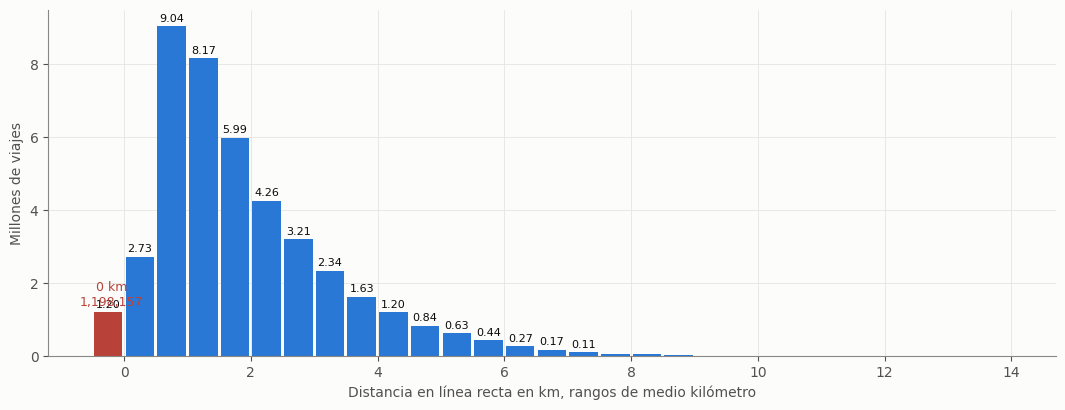

In [ ]:
# Viajes por distancia en rangos de medio kilómetro, los viajes con distancia 0 se cuentan aparte
distance_bin = F.when(F.col("distance_km") == 0, -0.5).otherwise(F.floor(F.col("distance_km") * 2) / 2)
distance_counts = (
    train_stations.filter(F.col("distance_km").isNotNull())
    .groupBy(distance_bin.alias("km"))
    .count()
    .orderBy("km")
    .toPandas()
)
zero_trips = distance_counts.loc[distance_counts["km"] == -0.5, "count"].sum()

# Figura 5, millones de viajes por distancia con los viajes de 0 km en rojo
figure, ax = plt.subplots(figsize=(13, 4.5))
colors = [RED if km == -0.5 else BLUE for km in distance_counts["km"]]
bars = ax.bar(distance_counts["km"] + 0.25, distance_counts["count"] / 1e6, width=0.45, color=colors)
ax.bar_label(bars, labels=[f"{value / 1e6:.2f}" if value >= 1e5 else "" for value in distance_counts["count"]], padding=2, fontsize=8)
ax.text(-0.2, zero_trips / 1e6 * 1.08, f"0 km\n{zero_trips:,}", color=RED, ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Distancia en línea recta en km, rangos de medio kilómetro")
ax.set_ylabel("Millones de viajes")
save_figure(figure, "results/graficas/figura_05_distancia.png")
plt.show()

Figura 5. Millones de viajes por distancia en línea recta en rangos de medio kilómetro, la barra roja son los viajes con distancia 0 que salen y llegan a la misma estación.

La distancia promedio es de 1.9 km con una desviación estándar de 1.42 km y el viaje más largo es de 13.7 km, Ecobici se usa para viajes cortos dentro de la zona donde están las estaciones, los viajes con distancia 0 forman una barra separada del resto y no son errores de captura sino viajes en los que el usuario regresó la bicicleta a la misma estación, con distancia 0 el modelo no tendría cómo relacionar la distancia con la duración y por eso se quitan en la limpieza.

## Limpieza

Los registros tienen viajes que no sirven para predecir la duración por errores del sistema o porque no son traslados de un punto a otro y se quitan con las siguientes reglas:

- La fecha y la hora de salida y de llegada se deben poder leer.

- La fecha de llegada debe estar dentro del mes del archivo, en la revisión se comprobó que cada archivo agrupa los viajes por la fecha de llegada y esta regla sirve como control por si algún archivo trae fechas equivocadas.

- Las dos estaciones deben estar en el catálogo porque sin su ubicación no se puede calcular la distancia.

- La estación de salida y la de llegada deben ser distintas, en un viaje redondo la distancia es 0 y la duración depende del paseo y no del recorrido.

- La duración debe estar entre 1 y 120 minutos, menos de un minuto suele ser una bicicleta que se tomó y se regresó por una falla y más de dos horas suele ser una bicicleta que no se devolvió a tiempo.

- La velocidad promedio debe estar entre 1 y 30 km/h, más de 30 km/h no es posible en bicicleta dentro de la ciudad y menos de 1 km/h indica que el usuario se detuvo o paseó en lugar de ir directo a su destino y como la distancia es en línea recta la velocidad calculada es menor que la real y por eso el límite inferior es bajo.

- La edad debe estar entre 16 y 90 años, en los datos hay edades de hasta 160 años que son errores de captura.

Los valores ? y vacíos del género no se quitan porque son el 1.1% de los viajes y la duración del viaje no depende de que el usuario haya dado su género, se juntan en la categoría `No especificado` al preparar las variables.

Los límites de cada regla se pueden cambiar en la siguiente celda.

Los viajes que no cumplen cada regla se cuentan en una sola pasada sobre los datos, un viaje puede fallar en más de una regla y por eso la suma de las reglas puede ser mayor que el total eliminado.

In [ ]:
# Límites de cada regla de limpieza
MIN_MINUTES, MAX_MINUTES = 1, 120
MIN_SPEED, MAX_SPEED = 1, 30
MIN_AGE, MAX_AGE = 16, 90

In [ ]:
def add_duration(df):
    ''' Calcula la duración en minutos y la velocidad promedio en km/h '''

    # Al convertir una fecha a número se obtienen los segundos, la resta entre 60 da los minutos
    duration = (F.col("dropoff").cast("long") - F.col("pickup").cast("long")) / 60

    return df.withColumn("duration_min", duration).withColumn("speed_kmh", F.col("distance_km") / (F.col("duration_min") / 60))


def cleaning_rules():
    ''' Regresa cada regla de limpieza como una condición que vale verdadero si el viaje es válido '''

    return {
        "fecha u hora que no se puede leer": F.col("pickup").isNotNull() & F.col("dropoff").isNotNull(),
        "llegada fuera del mes del archivo": F.date_format("dropoff", "yyyy-MM") == F.col("file_month"),
        "estación que no está en el catálogo": F.col("pickup_lat").isNotNull() & F.col("dropoff_lat").isNotNull(),
        "viaje redondo": F.col("pickup_station") != F.col("dropoff_station"),
        "duración fuera de 1 a 120 minutos": F.col("duration_min").between(MIN_MINUTES, MAX_MINUTES),
        "velocidad fuera de 1 a 30 km/h": F.col("speed_kmh").between(MIN_SPEED, MAX_SPEED),
        "edad fuera de 16 a 90 años": F.col("age").between(MIN_AGE, MAX_AGE),
    }


def valid_condition():
    ''' Une todas las reglas en una sola condición, un valor nulo cuenta como inválido '''

    return reduce(lambda left, right: left & right, [F.coalesce(rule, F.lit(False)) for rule in cleaning_rules().values()])

In [ ]:
# Se cuenta en una sola pasada cuántos viajes no cumplen cada regla y cuántos se eliminan en total
checked = add_duration(train_stations)
checks = [F.sum(F.when(F.coalesce(rule, F.lit(False)), 0).otherwise(1)).alias(name) for name, rule in cleaning_rules().items()]
checks.append(F.sum(F.when(valid_condition(), 0).otherwise(1)).alias("total eliminados"))

start = time.time()
report = checked.agg(*checks).collect()[0].asDict()
print(f"Revisión de las reglas en {time.time() - start:.1f} s")

# Tabla con los viajes eliminados por cada regla y su porcentaje respecto al total
raw_count = match["viajes"]
cleaning_report = pd.DataFrame({"regla": list(report.keys()), "viajes": list(report.values())})
cleaning_report["porcentaje"] = (cleaning_report["viajes"] / raw_count * 100).round(2)
cleaning_report

Revisión de las reglas en 51.7 s


,regla,viajes,porcentaje
0,fecha u hora que no se puede leer,0,0.00
1,llegada fuera del mes del archivo,0,0.00
2,estación que no está en el catálogo,1723,0.00
3,viaje redondo,1197103,2.82
4,duración fuera de 1 a 120 minutos,41003,0.10
5,velocidad fuera de 1 a 30 km/h,1763038,4.16
6,edad fuera de 16 a 90 años,3724,0.01
7,total eliminados,1777626,4.19


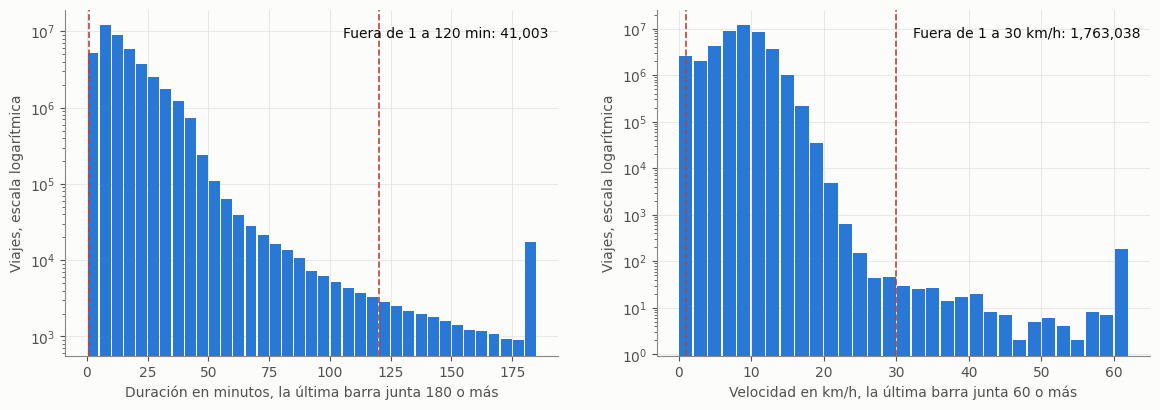

In [ ]:
# Viajes por duración en rangos de 5 minutos y por velocidad en rangos de 2 km/h, los valores muy altos se juntan en la última barra
duration_counts = (
    checked.filter(F.col("duration_min").isNotNull())
    .groupBy(F.greatest(F.least(F.floor(F.col("duration_min") / 5) * 5, F.lit(180)), F.lit(-5)).alias("minutos"))
    .count()
    .orderBy("minutos")
    .toPandas()
)
speed_counts = (
    checked.filter(F.col("speed_kmh").isNotNull())
    .groupBy(F.least(F.floor(F.col("speed_kmh") / 2) * 2, F.lit(60)).alias("kmh"))
    .count()
    .orderBy("kmh")
    .toPandas()
)

# Figura 6, distribución de la duración y de la velocidad en escala logarítmica con los límites de cada regla
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.bar(duration_counts["minutos"] + 2.5, duration_counts["count"], width=4.5, color=BLUE)
ax1.axvline(MIN_MINUTES, color=RED, linestyle="--", linewidth=1.2)
ax1.axvline(MAX_MINUTES, color=RED, linestyle="--", linewidth=1.2)
ax1.set_yscale("log")
ax1.set_xlabel("Duración en minutos, la última barra junta 180 o más")
ax1.set_ylabel("Viajes, escala logarítmica")
ax1.text(0.98, 0.95, f"Fuera de 1 a 120 min: {report['duración fuera de 1 a 120 minutos']:,}", transform=ax1.transAxes, ha="right", va="top")
ax2.bar(speed_counts["kmh"] + 1, speed_counts["count"], width=1.8, color=BLUE)
ax2.axvline(MIN_SPEED, color=RED, linestyle="--", linewidth=1.2)
ax2.axvline(MAX_SPEED, color=RED, linestyle="--", linewidth=1.2)
ax2.set_yscale("log")
ax2.set_xlabel("Velocidad en km/h, la última barra junta 60 o más")
ax2.set_ylabel("Viajes, escala logarítmica")
ax2.text(0.98, 0.95, f"Fuera de 1 a 30 km/h: {report['velocidad fuera de 1 a 30 km/h']:,}", transform=ax2.transAxes, ha="right", va="top")
save_figure(figure, "results/graficas/figura_06_duracion_y_velocidad.png")
plt.show()

Figura 6. Viajes por duración y por velocidad antes de la limpieza en escala logarítmica, las líneas punteadas marcan los límites de cada regla y la última barra de cada gráfica junta los valores más altos.

La escala logarítmica permite ver en la misma gráfica las barras con millones de viajes y las que tienen pocos, la mayoría de los viajes duran menos de 45 minutos que es el tiempo que permite un viaje sin cargo extra (Chilango, 2024) y la caída más marcada está justo después de ese tiempo, de 40 a 45 minutos hay unos 730 mil viajes y de 45 a 50 minutos baja a unos 240 mil, esto muestra que el límite de la tarifa influye en cuánto dura un viaje. Los viajes de más de 120 minutos son pocos y quedan lejos del resto lo que confirma que son bicicletas que no se devolvieron a tiempo y no traslados normales.

En la velocidad la mayoría de los viajes van de 6 a 12 km/h, la barra de 0 a 2 km/h incluye los 1.2 millones de viajes redondos que tienen velocidad 0 y por encima de 30 km/h solo hay unos cientos de viajes, sin contar los redondos quedan unos 566 mil viajes fuera de 1 a 30 km/h y casi todos son viajes muy lentos de alguien que se detuvo o paseó y no viajes demasiado rápidos.

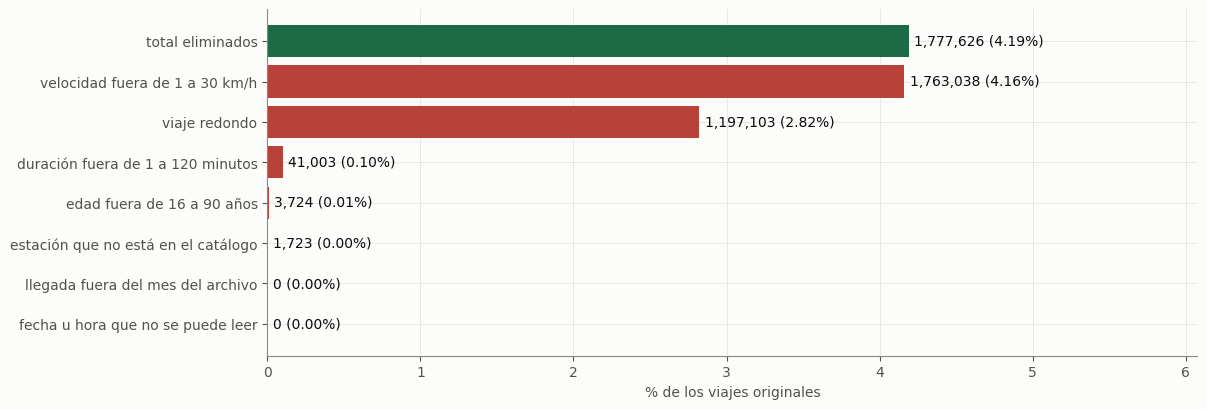

In [ ]:
# Figura 7, viajes que no cumple cada regla como porcentaje del total
table = cleaning_report.sort_values("viajes")
figure, ax = plt.subplots(figsize=(12, 4.5))
colors = [GREEN if rule == "total eliminados" else RED for rule in table["regla"]]
bars = ax.barh(table["regla"], table["porcentaje"], color=colors)
ax.bar_label(bars, labels=[f"{count:,} ({percent:.2f}%)" for count, percent in zip(table["viajes"], table["porcentaje"])], padding=4)
ax.set_xlabel("% de los viajes originales")
ax.set_xlim(0, table["porcentaje"].max() * 1.45)
save_figure(figure, "results/graficas/figura_07_limpieza.png")
plt.show()

Figura 7. Viajes que no cumple cada regla de limpieza y total eliminado como porcentaje de los 42.4 millones de viajes originales.

La regla de la velocidad marca el 4.16% y la de viajes redondos el 2.82% pero el total eliminado es 4.19% porque las reglas se traslapan, un viaje redondo tiene distancia 0 y por eso también velocidad 0 y cae en las dos reglas.

Las reglas de fecha no quitaron ningún viaje y la del catálogo solo quitó 1,723, esto indica que los archivos de Ecobici vienen bien capturados y que la mayor parte de lo que se quita no son errores sino viajes que no son traslados de un punto a otro. Casi el 3% de los viajes son redondos y esto muestra que una parte del uso de Ecobici es recreativo, para el operador son viajes que no mueven bicicletas entre estaciones y por eso no afectan la redistribución.

## Variables

El objetivo del modelo es la duración del viaje en minutos y las variables de entrada son datos que se conocen antes de que empiece el viaje como la distancia, la estación y la alcaldía de salida y de llegada, la hora, el día de la semana, el mes, si es fin de semana y la edad y el género del usuario que están registrados en su cuenta, la distancia exacta no se conoce antes del viaje pero una aplicación la puede estimar con la ubicación de las dos estaciones como se hizo aquí.

La hora de llegada no se usa porque con ella y la hora de salida se obtiene directamente la duración y el modelo aprendería la respuesta con un dato que no existe al momento de predecir lo que comúnmente se le conoce como fuga de información, la velocidad tampoco se usa porque se calculó con la duración.

El género se deja con nombres completos y los valores ? y vacíos se juntan en la categoría `No especificado` así el tablero se entiende sin conocer los códigos del archivo original.

En la columna day_of_week el 1 es domingo y el 7 es sábado.

In [ ]:
def add_features(df):
    ''' Agrega la hora, el día, el mes y el género con nombre completo a cada viaje '''

    # Los valores ? y vacíos del género quedan en la categoría No especificado
    gender = (
        F.when(F.col("gender") == "M", "Masculino")
        .when(F.col("gender") == "F", "Femenino")
        .when(F.col("gender") == "O", "Otro")
        .otherwise("No especificado")
    )

    df = (
        df.withColumn("gender", gender)
        .withColumn("hour", F.hour("pickup"))
        .withColumn("day_of_week", F.dayofweek("pickup"))
        .withColumn("month", F.month("pickup"))
        .withColumn("year", F.year("pickup"))
        .withColumn("is_weekend", F.col("day_of_week").isin(1, 7).cast("int"))
    )

    return df.drop("speed_kmh")


def prepare(df):
    ''' Agrega las estaciones, aplica la limpieza y agrega las variables a un DataFrame de viajes '''

    return add_features(add_duration(add_stations(df)).filter(valid_condition()))

El plan físico muestra cómo va a ejecutar Spark la consulta y se revisa con un solo mes porque los 24 meses tienen el mismo plan y con todos el resultado sería muy largo.

En FileScan parquet la línea ReadSchema muestra las columnas que se leen y BroadcastHashJoin confirma que el catálogo se manda completo a cada tarea.

In [ ]:
prepare(train_raw.filter(F.col("file_month") == train_months[0])).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [dropoff_station#5358, pickup_station#5357, gender#6196, age#5356, pickup#5359, dropoff#5360, file_month#5361, pickup_colonia#5618, pickup_alcaldia#5619, pickup_lat#5620, pickup_lon#5621, dropoff_colonia#5628, dropoff_alcaldia#5629, dropoff_lat#5630, dropoff_lon#5631, distance_km#6142, duration_min#6159, hour#6215, day_of_week#6235, month#6256, year#6278, cast(day_of_week#6235 IN (1,7) as int) AS is_weekend#6301]
   +- Project [dropoff_station#5358, pickup_station#5357, CASE WHEN (gender#5355 = M) THEN Masculino WHEN (gender#5355 = F) THEN Femenino WHEN (gender#5355 = O) THEN Otro ELSE No especificado END AS gender#6196, age#5356, pickup#5359, dropoff#5360, file_month#5361, pickup_colonia#5618, pickup_alcaldia#5619, pickup_lat#5620, pickup_lon#5621, dropoff_colonia#5628, dropoff_alcaldia#5629, dropoff_lat#5630, dropoff_lon#5631, (ASIN(SQRT((POWER(SIN((RADIANS((dropoff_lat#5630 - pickup_lat#5620)) / 2.0)), 2.0) + ((COS(R

Los datos limpios se guardan en Parquet particionado por el mes del archivo así las siguientes secciones leen datos que ya están limpios y no repiten la unión con el catálogo ni la limpieza y a los viajes de enero de 2026 se les aplica la misma limpieza para que se evalúen igual que los de entrenamiento.

In [ ]:
# Carpetas de los datos limpios
CLEAN_DIR = DATA_DIR / "limpio"

# Se limpian los 24 meses y se guardan en Parquet particionado por mes
start = time.time()
prepare(train_raw).write.mode("overwrite").partitionBy("file_month").parquet(str(CLEAN_DIR / "entrenamiento"))
print(f"Limpieza y guardado del entrenamiento en {time.time() - start:.0f} s")

# Se aplica la misma limpieza al mes de las predicciones
start = time.time()
predict_raw = spark.read.parquet(str(PARQUET_DIR / "prediccion"))
prepare(predict_raw).write.mode("overwrite").parquet(str(CLEAN_DIR / "prediccion"))
print(f"Limpieza y guardado de {PREDICT_MONTH} en {time.time() - start:.0f} s")

Limpieza y guardado del entrenamiento en 440 s
Limpieza y guardado de 2026-01 en 14 s


In [ ]:
# Se leen los datos limpios desde el disco para las siguientes secciones
train = spark.read.parquet(str(CLEAN_DIR / "entrenamiento"))
predict = spark.read.parquet(str(CLEAN_DIR / "prediccion"))
train.printSchema()
train.select("pickup", "duration_min", "distance_km", "pickup_alcaldia", "dropoff_alcaldia", "hour", "day_of_week", "age", "gender").show(5)

root
 |-- dropoff_station: string (nullable = true)
 |-- pickup_station: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- pickup: timestamp (nullable = true)
 |-- dropoff: timestamp (nullable = true)
 |-- pickup_colonia: string (nullable = true)
 |-- pickup_alcaldia: string (nullable = true)
 |-- pickup_lat: double (nullable = true)
 |-- pickup_lon: double (nullable = true)
 |-- dropoff_colonia: string (nullable = true)
 |-- dropoff_alcaldia: string (nullable = true)
 |-- dropoff_lat: double (nullable = true)
 |-- dropoff_lon: double (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- duration_min: double (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- is_weekend: integer (nullable = true)
 |-- file_month: string (nullable = true)

+-------------------+------------------+------------------

## Resumen del procesamiento

In [ ]:
# Viajes antes y después de la limpieza y peso de los datos en cada etapa
train_count = train.count()
predict_count = predict.count()
print(f"Entrenamiento: {raw_count:,} viajes originales y {train_count:,} limpios, se eliminó el {(1 - train_count / raw_count) * 100:.2f}%")
print(f"Predicciones {PREDICT_MONTH}: {raw_counts[PREDICT_MONTH]:,} viajes originales y {predict_count:,} limpios")
print(f"Peso del CSV original: {train_gb:.2f} GB")
print(f"Peso del Parquet sin limpiar: {parquet_gb:.2f} GB")
print(f"Peso del Parquet limpio: {folder_size_gb(CLEAN_DIR / 'entrenamiento'):.2f} GB")

Entrenamiento: 42,377,769 viajes originales y 40,600,143 limpios, se eliminó el 4.19%
Predicciones 2026-01: 1,525,302 viajes originales y 1,463,259 limpios
Peso del CSV original: 2.48 GB
Peso del Parquet sin limpiar: 0.56 GB
Peso del Parquet limpio: 1.02 GB


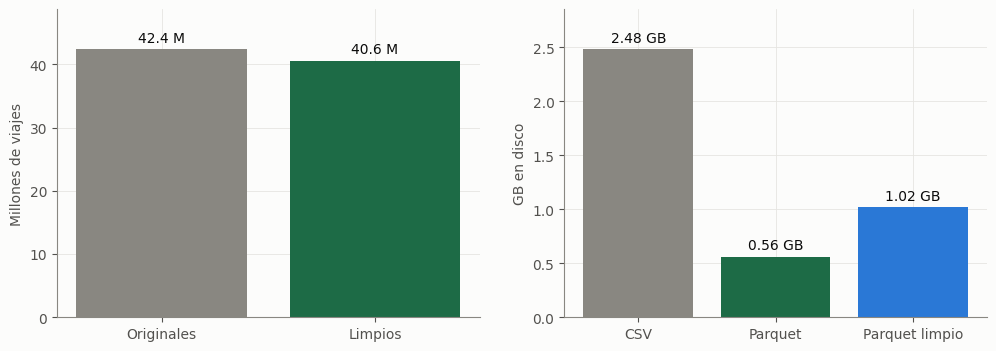

In [ ]:
# Figura 8, viajes y peso de los datos en cada etapa del procesamiento
clean_gb = folder_size_gb(CLEAN_DIR / "entrenamiento")
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
bars = ax1.bar(["Originales", "Limpios"], [raw_count / 1e6, train_count / 1e6], color=[GRAY, GREEN])
ax1.bar_label(bars, labels=[f"{raw_count / 1e6:.1f} M", f"{train_count / 1e6:.1f} M"], padding=3)
ax1.set_ylabel("Millones de viajes")
ax1.set_ylim(0, raw_count / 1e6 * 1.15)
bars = ax2.bar(["CSV", "Parquet", "Parquet limpio"], [train_gb, parquet_gb, clean_gb], color=[GRAY, GREEN, BLUE])
ax2.bar_label(bars, labels=[f"{value:.2f} GB" for value in [train_gb, parquet_gb, clean_gb]], padding=3)
ax2.set_ylabel("GB en disco")
ax2.set_ylim(0, train_gb * 1.15)
save_figure(figure, "results/graficas/figura_08_etapas.png")
plt.show()

Figura 8. Millones de viajes antes y después de la limpieza y peso en GB de los datos de entrenamiento en cada etapa.

Después de la limpieza quedan 40.6 millones de viajes que son el 95.8% de los originales, el Parquet limpio pesa 1.02 GB, más que el Parquet sin limpiar de 0.56 GB aunque tiene menos viajes, porque cada viaje ahora guarda la colonia, la alcaldía y las coordenadas de sus dos estaciones, la distancia, la duración y las variables nuevas, aun así pesa el 41% del CSV original y las siguientes secciones ya no tienen que repetir la unión con el catálogo ni la limpieza.

## Análisis de los datos

Antes de entrenar se analizan todos los viajes limpios con Spark para conocer cómo se usa el sistema y para generar las tablas del tablero de tableau.

Las tablas guardan totales de viajes, minutos y kilómetros en lugar de promedios porque en Tableau se pueden filtrar varios meses o alcaldías a la vez y si se guardaran promedios Tableau promediaría los promedios y el resultado sería incorrecto entonces el promedio se calcula en Tableau dividiendo el total entre los viajes.

La primera tabla agrupa los viajes por fecha, hora y alcaldía de salida, con ella Tableau arma los indicadores generales, el mapa de calor por día y hora y la tendencia mensual y permite filtrar por año, mes, día de la semana y alcaldía.

In [ ]:
# Viajes, minutos y kilómetros por fecha, hora y alcaldía de salida
start = time.time()
demand = (
    train.groupBy(F.to_date("pickup").alias("fecha"), F.col("hour").alias("hora"), F.col("pickup_alcaldia").alias("alcaldia_salida"))
    .agg(
        F.count("*").alias("viajes"),
        F.round(F.sum("duration_min"), 2).alias("minutos_totales"),
        F.round(F.sum("distance_km"), 2).alias("km_totales"),
    )
    .orderBy("fecha", "hora", "alcaldia_salida")
    .toPandas()
)
print(f"Demanda: {len(demand):,} filas en {time.time() - start:.1f} s")
save_table(demand, "tableau/datos/demanda.csv")
demand.head()

Demanda: 87,296 filas en 24.8 s
Guardado tableau/datos/demanda.csv con 87,296 filas


,fecha,hora,alcaldia_salida,viajes,minutos_totales,km_totales
0,2023-12-31,23,Benito Juarez,5,140.93,21.80
1,2023-12-31,23,Cuauhtemoc,39,1246.10,107.00
2,2023-12-31,23,Miguel Hidalgo,6,187.93,13.81
3,2024-01-01,0,Benito Juarez,11,182.65,28.91
4,2024-01-01,0,Coyoacan,1,24.98,1.48


In [ ]:
# Indicadores generales de los dos años, el total de viajes debe coincidir con el conteo de los datos limpios
total_trips = demand["viajes"].sum()
print(f"Viajes: {total_trips:,}, coincide con los datos limpios: {total_trips == train_count}")
print(f"Duración promedio: {demand['minutos_totales'].sum() / total_trips:.1f} minutos")
print(f"Distancia promedio: {demand['km_totales'].sum() / total_trips:.2f} km")
print(f"Viajes por día en promedio: {total_trips / demand['fecha'].nunique():,.0f}")

Viajes: 40,600,143, coincide con los datos limpios: True
Duración promedio: 14.6 minutos
Distancia promedio: 1.97 km
Viajes por día en promedio: 55,465


Después de la limpieza quedan 40,600,143 viajes de 2024 y 2025, un viaje dura en promedio 14.6 minutos y recorre 1.97 km en línea recta y en un día hay en promedio 55,465 viajes.

Las primeras filas de la tabla son del 31 de diciembre de 2023 porque son viajes que salieron ese día y llegaron el 1 de enero de 2024.

La distancia promedio entre la duración promedio da 8.1 km/h en línea recta, es menor que la velocidad de una bicicleta en movimiento porque la ruta real es más larga que la línea recta y porque el viaje incluye semáforos y paradas. El promedio de 14.6 minutos queda muy por debajo de los 45 minutos que permite un viaje sin cargo extra (Chilango, 2024), esto indica que Ecobici se usa sobre todo para traslados cortos y no para recorridos largos.

La segunda tabla agrupa los viajes por año, mes y estación de salida con su colonia, su alcaldía, su latitud y su longitud, con ella Tableau dibuja el mapa de las estaciones y muestra las que tienen más viajes según el filtro que se elija.

In [ ]:
# Viajes y minutos por año, mes y estación de salida con su ubicación
start = time.time()
stations_table = (
    train.groupBy(
        F.col("year").alias("año"),
        F.col("month").alias("mes"),
        F.col("pickup_station").alias("estacion"),
        F.col("pickup_colonia").alias("colonia"),
        F.col("pickup_alcaldia").alias("alcaldia"),
        F.col("pickup_lat").alias("latitud"),
        F.col("pickup_lon").alias("longitud"),
    )
    .agg(F.count("*").alias("viajes"), F.round(F.sum("duration_min"), 2).alias("minutos_totales"))
    .orderBy("año", "mes", F.desc("viajes"))
    .toPandas()
)
print(f"Estaciones: {len(stations_table):,} filas en {time.time() - start:.1f} s")
save_table(stations_table, "tableau/datos/estaciones.csv")

# Las 10 estaciones con más viajes en los dos años
stations_table.groupby(["estacion", "colonia", "alcaldia"])["viajes"].sum().sort_values(ascending=False).head(10)

Estaciones: 16,197 filas en 28.0 s
Guardado tableau/datos/estaciones.csv con 16,197 filas


,,,viajes
estacion,colonia,alcaldia,
271-272,Buenavista,Cuauhtemoc,379334
27,Juarez,Cuauhtemoc,232913
64,Hipodromo,Cuauhtemoc,223050
548,Santa Maria la Ribera,Cuauhtemoc,212132
237-238,Polanco,Miguel Hidalgo,202008
208,Polanco,Miguel Hidalgo,196556
14,Cuauhtemoc,Cuauhtemoc,187950
31,Juarez,Cuauhtemoc,186384
192-193,Bosque de Chapultepec,Miguel Hidalgo,185438


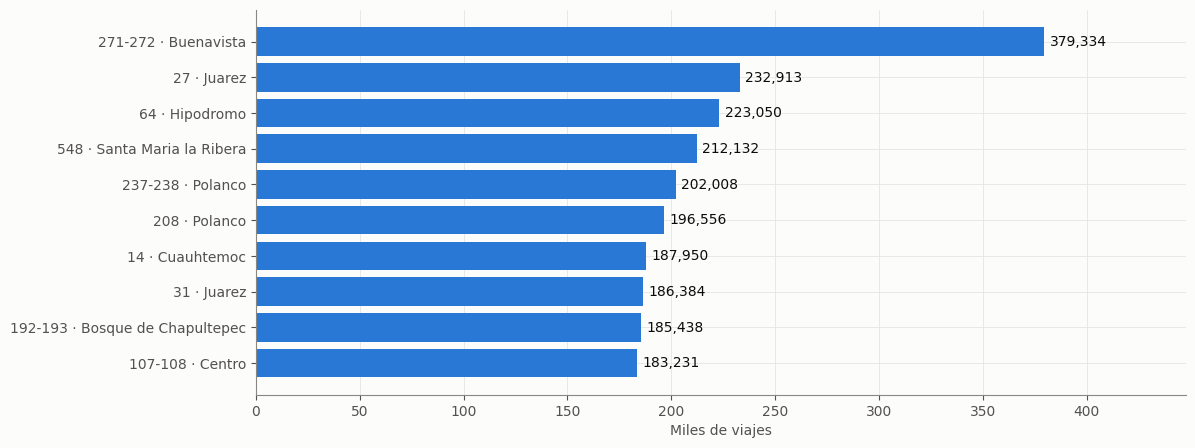

In [ ]:
# Figura 9, las 10 estaciones con más viajes en los dos años
top = stations_table.groupby(["estacion", "colonia"], as_index=False)["viajes"].sum().sort_values("viajes").tail(10)
figure, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top["estacion"] + " · " + top["colonia"], top["viajes"] / 1e3, color=BLUE)
ax.bar_label(bars, labels=[f"{value:,}" for value in top["viajes"]], padding=4)
ax.set_xlabel("Miles de viajes")
ax.set_xlim(0, top["viajes"].max() / 1e3 * 1.18)
save_figure(figure, "results/graficas/figura_09_estaciones.png")
plt.show()

Figura 9. Viajes que salieron de las 10 estaciones más usadas en 2024 y 2025, cada barra tiene el número de la estación y su colonia.

La estación con más viajes es la 271-272 en la colonia Buenavista con 379,334 viajes en los dos años, la Secretaría de Movilidad reporta que es la más usada del sistema porque conecta con otros transportes públicos.

Siete de las diez estaciones con más viajes están en la alcaldía Cuauhtémoc y las otras tres en Miguel Hidalgo que son las alcaldías del centro de la ciudad.

La estación de Buenavista tiene 1.6 veces los viajes de la segunda y entre las diez suman 2.19 millones de viajes, el 5.4% del total con solo el 1.5% de las 677 estaciones.

La demanda se concentra en pocas estaciones y en ellas una estación vacía o llena afecta a más usuarios, por eso son las primeras que conviene vigilar al redistribuir bicicletas, cuatro de las diez son estaciones dobles, 271-272, 237-238, 192-193 y 107-108, que tienen más lugares para tomar y dejar bicicletas.

La tercera tabla agrupa los viajes por año, mes, género y grupo de edad para conocer quién usa el sistema, la edad se agrupa en rangos de diez años para que la tabla sea fácil de leer en el tablero.

In [ ]:
# Grupo de edad en rangos de diez años
age_group = (
    F.when(F.col("age") < 25, "16 a 24")
    .when(F.col("age") < 35, "25 a 34")
    .when(F.col("age") < 45, "35 a 44")
    .when(F.col("age") < 55, "45 a 54")
    .when(F.col("age") < 65, "55 a 64")
    .otherwise("65 o más")
)

# Viajes y minutos por año, mes, género y grupo de edad
start = time.time()
users_table = (
    train.groupBy(F.col("year").alias("año"), F.col("month").alias("mes"), F.col("gender").alias("genero"), age_group.alias("grupo_edad"))
    .agg(F.count("*").alias("viajes"), F.round(F.sum("duration_min"), 2).alias("minutos_totales"))
    .orderBy("año", "mes", "genero", "grupo_edad")
    .toPandas()
)
print(f"Usuarios: {len(users_table):,} filas en {time.time() - start:.1f} s")
save_table(users_table, "tableau/datos/usuarios.csv")

# Viajes por género y por grupo de edad en los dos años
print(users_table.groupby("genero")["viajes"].sum().sort_values(ascending=False))
print(users_table.groupby("grupo_edad")["viajes"].sum())

Usuarios: 549 filas en 11.2 s
Guardado tableau/datos/usuarios.csv con 549 filas
genero
Masculino          27848738
Femenino           11522856
Otro                 779437
No especificado      449112
Name: viajes, dtype: int64
grupo_edad
16 a 24      5620916
25 a 34     19394865
35 a 44     10051403
45 a 54      3810018
55 a 64      1401544
65 o más      321397
Name: viajes, dtype: int64


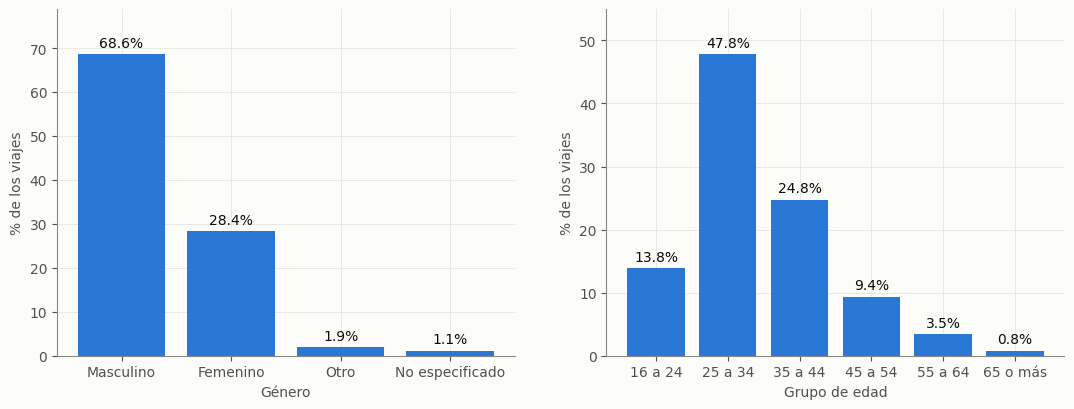

In [ ]:
# Figura 10, porcentaje de los viajes por género y por grupo de edad
by_gender = users_table.groupby("genero")["viajes"].sum().sort_values(ascending=False)
by_age = users_table.groupby("grupo_edad")["viajes"].sum().sort_index()
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, series, xlabel in [(ax1, by_gender, "Género"), (ax2, by_age, "Grupo de edad")]:
    percent = series / series.sum() * 100
    bars = ax.bar(series.index, percent, color=BLUE)
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in percent], padding=3)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% de los viajes")
    ax.set_ylim(0, percent.max() * 1.15)
save_figure(figure, "results/graficas/figura_10_usuarios.png")
plt.show()

Figura 10. Porcentaje de los viajes limpios por género y por grupo de edad.

El 68.6% de los viajes los hacen hombres y el 28.4% mujeres, el grupo de 25 a 34 años hace casi la mitad de los viajes con el 47.8% y los usuarios de 65 años o más hacen menos del 1%.

Las personas de 25 a 44 años hacen el 72.6% de los viajes y esto tiene dos consecuencias, para el operador indica que las campañas para atraer usuarios nuevos tienen más espacio en las mujeres y en las personas mayores de 45 años y para el modelo indica que aprende sobre todo del comportamiento de hombres de 25 a 44 años, con menos del 1% de viajes de personas de 65 años o más sus predicciones para ese grupo se basan en pocos ejemplos y son menos confiables.

Para la Figura 11 primero se suman los viajes de todas las alcaldías en cada fecha y hora y después se promedian entre todas las fechas que caen en el mismo día de la semana así cada cuadro es el número de viajes que hay en promedio un día de esos a esa hora.

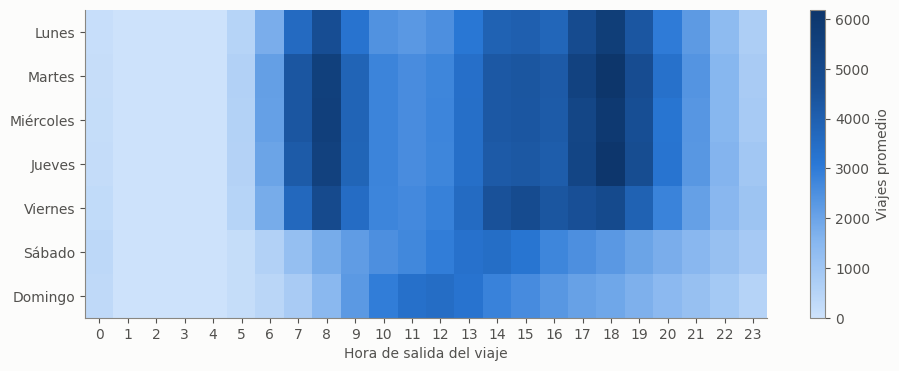

In [ ]:
# Viajes por fecha y hora de 2024 y 2025 sumando todas las alcaldías
by_hour = demand.groupby(["fecha", "hora"], as_index=False)["viajes"].sum()
by_hour["fecha"] = pd.to_datetime(by_hour["fecha"])
by_hour = by_hour[by_hour["fecha"].dt.year.isin([2024, 2025])]
by_hour["dia"] = by_hour["fecha"].dt.dayofweek

# Total de viajes por día de la semana y hora con las 24 horas aunque alguna no tenga viajes
totals = by_hour.groupby(["dia", "hora"])["viajes"].sum().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)

# Se divide entre el número de lunes, martes, etc. del periodo para obtener el promedio por día
days_count = pd.Series(by_hour["fecha"].unique()).dt.dayofweek.value_counts().sort_index()
heatmap = totals.div(days_count, axis=0)

figure, ax = plt.subplots(figsize=(11, 4))
image = ax.imshow(heatmap.values, aspect="auto", cmap=BLUES)
ax.grid(False)
ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAY_LABELS)
ax.set_xlabel("Hora de salida del viaje")
figure.colorbar(image, ax=ax, label="Viajes promedio")
save_figure(figure, "results/graficas/figura_11_demanda_dia_hora.png")
plt.show()

Figura 11. Viajes promedio por día de la semana y hora de salida en 2024 y 2025, entre más oscuro es el cuadro hay más viajes.

En la Figura 11 se ve que entre semana hay dos horas pico, una a las 8 de la mañana y otra de las 17 a las 19 horas que corresponden a los horarios de entrada y salida del trabajo y la escuela, esto indica que gran parte de los usuarios usa Ecobici para trasladarse y no solo para pasear, el pico de la tarde dura más que el de la mañana, esto puede indicar que las horas de salida del trabajo y la escuela están más repartidas que las de entrada.

Los fines de semana hay menos viajes y se concentran entre las 10 y las 15 horas, de la 1 a las 4 de la mañana casi no hay viajes porque el sistema opera de las 5:00 a las 00:30 (Chilango, 2024).

Para el operador esto significa que la redistribución de bicicletas tiene que estar lista antes de las 7 de la mañana y antes de las 17 horas entre semana, los patrones de la mañana y de la tarde sugieren que las bicicletas se mueven hacia el centro en la mañana y de regreso en la tarde, para confirmarlo se tendrían que comparar las salidas y las llegadas de cada estación por hora.

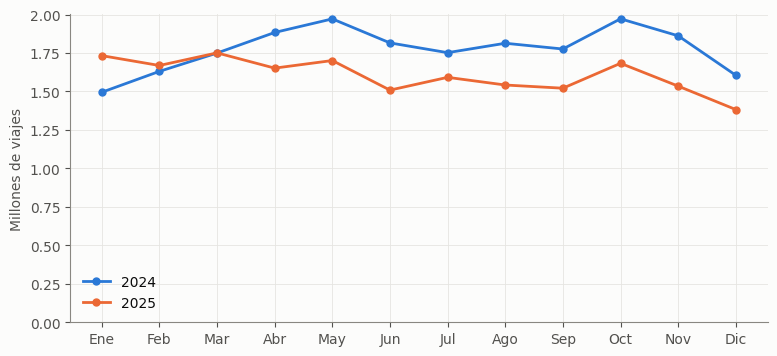

In [ ]:
# Viajes por mes de cada año
dates = pd.to_datetime(demand["fecha"])
monthly = demand.groupby([dates.dt.year.rename("year"), dates.dt.month.rename("month")])["viajes"].sum().unstack(0)

# Solo se grafican 2024 y 2025, los pocos viajes que salieron en diciembre de 2023 y llegaron en enero de 2024 no forman un año
monthly = monthly[[2024, 2025]]

figure, ax = plt.subplots(figsize=(9, 4))
for year, color in zip(monthly.columns, [BLUE, ORANGE]):
    ax.plot(monthly.index, monthly[year] / 1e6, color=color, linewidth=2, marker="o", markersize=5, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTH_LABELS)
ax.set_ylim(0)
ax.set_ylabel("Millones de viajes")
ax.legend(frameon=False)
save_figure(figure, "results/graficas/figura_12_viajes_por_mes.png")
plt.show()

Figura 12. Millones de viajes limpios por mes en 2024 y 2025.

En 2024 hubo más viajes que en 2025 en casi todos los meses y solo en enero fue al revés, los meses con más viajes fueron mayo y octubre de 2024 y el de menos viajes fue diciembre de 2025, con estos datos no se puede saber la causa de la baja en 2025 porque no incluyen información sobre el número de bicicletas disponibles, las tarifas o el clima.

La forma de las dos líneas es parecida, en los dos años diciembre está entre los meses con menos viajes y los meses de vacaciones escolares no son los más altos, esto refuerza que la mayoría de los viajes son traslados al trabajo y la escuela como se vio en la Figura 11.

Para el operador los meses con menos viajes pueden ser los mejores para dar mantenimiento a las bicicletas y a las estaciones porque se afecta a menos usuarios.

## Relación entre la distancia y la duración

Antes de entrenar los modelos se revisa cómo se relaciona la distancia con la duración porque es la variable que más se espera que influya, se calcula la correlación de Pearson con todos los viajes limpios y se agrupan los viajes en rangos de un cuarto de kilómetro para calcular la duración promedio de cada rango.

La correlación de Pearson mide qué tan cerca están dos variables de una relación en línea recta, vale 1 si una sube siempre en proporción con la otra y 0 si no tienen relación lineal.

Correlación entre distancia y duración: 0.729
Viajes de menos de 8 km: 99.7%


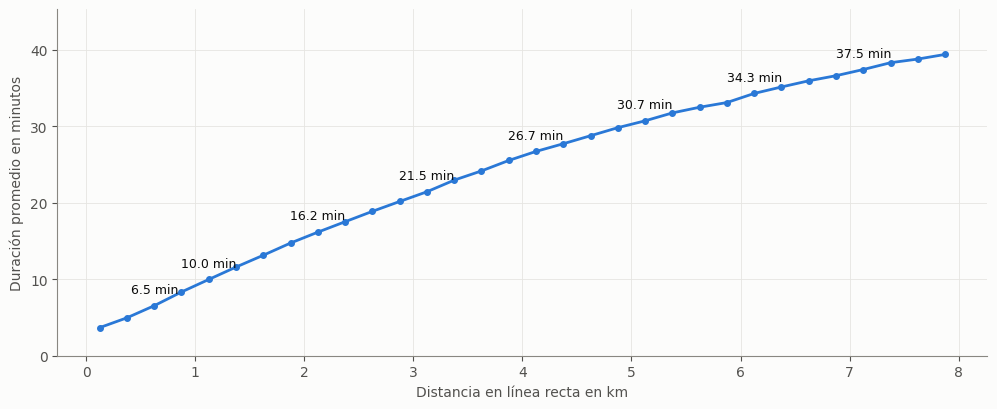

In [ ]:
# Correlación entre la distancia y la duración con todos los viajes limpios
correlation = train.stat.corr("distance_km", "duration_min")
print(f"Correlación entre distancia y duración: {correlation:.3f}")

# Duración promedio y viajes por rango de un cuarto de kilómetro hasta 8 km
by_distance = (
    train.filter(F.col("distance_km") < 8)
    .groupBy((F.floor(F.col("distance_km") * 4) / 4).alias("km"))
    .agg(F.count("*").alias("viajes"), F.avg("duration_min").alias("duracion"))
    .orderBy("km")
    .toPandas()
)
print(f"Viajes de menos de 8 km: {by_distance['viajes'].sum() / train_count * 100:.1f}%")

# Figura 13, duración promedio por rango de distancia con el valor cada kilómetro
figure, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(by_distance["km"] + 0.125, by_distance["duracion"], color=BLUE, marker="o", markersize=4, linewidth=2)
for _, row in by_distance[by_distance["km"].isin([0.5, 1, 2, 3, 4, 5, 6, 7])].iterrows():
    ax.annotate(f"{row['duracion']:.1f} min", (row["km"] + 0.125, row["duracion"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xlabel("Distancia en línea recta en km")
ax.set_ylabel("Duración promedio en minutos")
ax.set_ylim(0, by_distance["duracion"].max() * 1.15)
save_figure(figure, "results/graficas/figura_13_distancia_duracion.png")
plt.show()

Figura 13. Duración promedio de los viajes limpios por rango de distancia de un cuarto de kilómetro, cada kilómetro se escribe su duración promedio.

La correlación entre la distancia y la duración es de 0.729 que indica una relación fuerte, en la Figura 13 se ve que la duración crece casi en línea recta con la distancia, un viaje de 1 km dura en promedio 10 minutos, uno de 3 km dura 21.5 y uno de 5 km dura 30.7.

En los primeros 3 km cada kilómetro agrega entre 5.5 y 6 minutos y a partir de los 5 km agrega unos 3.5 minutos probablemente porque en los viajes largos el ciclista avanza más tiempo sin detenerse y su velocidad promedio es mayor, el 99.7% de los viajes miden menos de 8 km.

Al elevar la correlación al cuadrado se obtiene 0.53, esto quiere decir que la distancia sola ya explica alrededor del 53% de la variación de la duración y se espera que la regresión lineal funcione bien y que el resto de las variables agregue poco, esto se comprueba más adelante en las Figuras 15 y 16.

## Modelos con MLlib

Se comparan dos modelos de regresión primero una regresión lineal como modelo base porque es el modelo más simple y después un Random Forest que es un conjunto de árboles de decisión que puede aprender relaciones que no son lineales y combinaciones entre variables por ejemplo que la misma distancia tarde más en una hora pico que en la madrugada.

Las variables categóricas como la estación, la hora o el día se convierten a números con StringIndexer que le asigna un índice a cada valor en la regresión lineal además se usa OneHotEncoder que convierte cada índice en columnas de ceros y unos porque si la hora entrara como número el modelo supondría que la duración sube o baja en línea recta con la hora, el Random Forest no necesita OneHotEncoder porque los árboles separan las categorías directamente.

En la regresión lineal no se usan la alcaldía ni el fin de semana porque se obtienen de otras variables, la alcaldía sale de la estación y el fin de semana sale del día de la semana, si se usaran el modelo tendría columnas que se pueden calcular con otras y a esto se le llama multicolinealidad, el Random Forest sí las usa porque los árboles no tienen este problema.

En StringIndexer se usa handleInvalid igual a keep para que una estación que no apareció en la muestra de entrenamiento no detenga las predicciones de enero de 2026.

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor

In [ ]:
# Variables de cada modelo, tamaño de la prueba, tamaño de la muestra final y semilla
LABEL = "duration_min"
NUMERIC_LR = ["distance_km", "age"]
CATEGORICAL_LR = ["pickup_station", "dropoff_station", "hour", "day_of_week", "month", "gender"]
NUMERIC_RF = ["distance_km", "age", "is_weekend"]
CATEGORICAL_RF = CATEGORICAL_LR + ["pickup_alcaldia", "dropoff_alcaldia"]
TEST_SIZE = 200_000
SAMPLE_SIZE = 10_000_000
SEED = 42

In [ ]:
def linear_pipeline():
    ''' Arma el pipeline de la regresión lineal con índices, one hot y el vector de variables '''

    indexed = [f"{column}_index" for column in CATEGORICAL_LR]
    encoded = [f"{column}_onehot" for column in CATEGORICAL_LR]
    indexer = StringIndexer(inputCols=CATEGORICAL_LR, outputCols=indexed, handleInvalid="keep")
    encoder = OneHotEncoder(inputCols=indexed, outputCols=encoded)
    assembler = VectorAssembler(inputCols=NUMERIC_LR + encoded, outputCol="features")
    model = LinearRegression(featuresCol="features", labelCol=LABEL)

    return Pipeline(stages=[indexer, encoder, assembler, model])


def forest_pipeline():
    ''' Arma el pipeline del Random Forest con índices y el vector de variables '''

    indexed = [f"{column}_index" for column in CATEGORICAL_RF]
    indexer = StringIndexer(inputCols=CATEGORICAL_RF, outputCols=indexed, handleInvalid="keep")
    assembler = VectorAssembler(inputCols=NUMERIC_RF + indexed, outputCol="features")

    # maxBins debe ser mayor que el número de categorías de la variable con más valores que son las 677 estaciones
    model = RandomForestRegressor(featuresCol="features", labelCol=LABEL, numTrees=20, maxDepth=10, maxBins=700, seed=SEED)

    return Pipeline(stages=[indexer, assembler, model])


def make_sample(size):
    ''' Toma una muestra aleatoria de viajes y la divide en 80% para entrenar y 20% para evaluar '''

    # Solo se guardan en memoria las columnas que usan los modelos
    columns = [LABEL] + NUMERIC_RF + CATEGORICAL_RF
    sample = train.select(columns).sample(fraction=min(size / train_count, 1.0), seed=SEED)
    train_part, test_part = sample.randomSplit([0.8, 0.2], seed=SEED)

    return train_part.cache(), test_part.cache()

Con 2 núcleos y 7 GB de memoria entrenar con los 40 millones de viajes tardaría demasiado y podría no caber en la memoria, por eso los modelos se entrenan con una muestra aleatoria de 10 millones de viajes.

Primero se hace una prueba con 200 mil viajes para medir cuánto tarda cada modelo y con ese tiempo se estima cuánto tardará la muestra final, la estimación es aproximada porque una parte del tiempo es preparación que no depende del número de viajes.

Las muestras se guardan en memoria con cache porque los modelos recorren los mismos datos varias veces durante el entrenamiento y así Spark no los vuelve a leer del disco en cada recorrido.

In [ ]:
# Prueba con una muestra pequeña para medir cuánto tarda cada modelo
train_part, test_part = make_sample(TEST_SIZE)
print(f"Prueba con {train_part.count():,} viajes de entrenamiento y {test_part.count():,} de evaluación")
test_times = {}
for name, pipeline in [("Regresión lineal", linear_pipeline()), ("Random Forest", forest_pipeline())]:
    start = time.time()
    pipeline.fit(train_part)
    test_times[name] = time.time() - start
    print(f"{name}: {test_times[name]:.0f} s")
train_part.unpersist()
test_part.unpersist()

# Tiempo estimado de cada modelo con la muestra final
print()
for name, seconds in test_times.items():
    print(f"{name} con {SAMPLE_SIZE:,} viajes: unos {seconds * SAMPLE_SIZE / TEST_SIZE / 60:.0f} minutos")

Prueba con 160,983 viajes de entrenamiento y 39,878 de evaluación
Regresión lineal: 20 s
Random Forest: 141 s

Regresión lineal con 10,000,000 viajes: unos 17 minutos
Random Forest con 10,000,000 viajes: unos 118 minutos


Cada modelo se guarda en disco al terminar de entrenar y se copia a Drive, si Colab se desconecta mientras entrena el Random Forest la regresión lineal ya queda guardada.

In [ ]:
# Muestra final con la que se entrenan los dos modelos
train_part, test_part = make_sample(SAMPLE_SIZE)
train_rows, test_rows = train_part.count(), test_part.count()
print(f"Muestra final con {train_rows:,} viajes de entrenamiento y {test_rows:,} de evaluación")

# Se entrena cada modelo, se mide su tiempo y se guarda
models = {}
train_seconds = {}
for name, folder, pipeline in [("Regresión lineal", "regresion_lineal", linear_pipeline()), ("Random Forest", "random_forest", forest_pipeline())]:
    start = time.time()
    models[name] = pipeline.fit(train_part)
    train_seconds[name] = time.time() - start
    models[name].write().overwrite().save(str(MODEL_DIR / folder))
    backup(MODEL_DIR / folder)
    print(f"{name} entrenado en {train_seconds[name] / 60:.1f} minutos")

Muestra final con 8,002,656 viajes de entrenamiento y 2,000,445 de evaluación
Regresión lineal entrenado en 2.6 minutos
Random Forest entrenado en 27.8 minutos


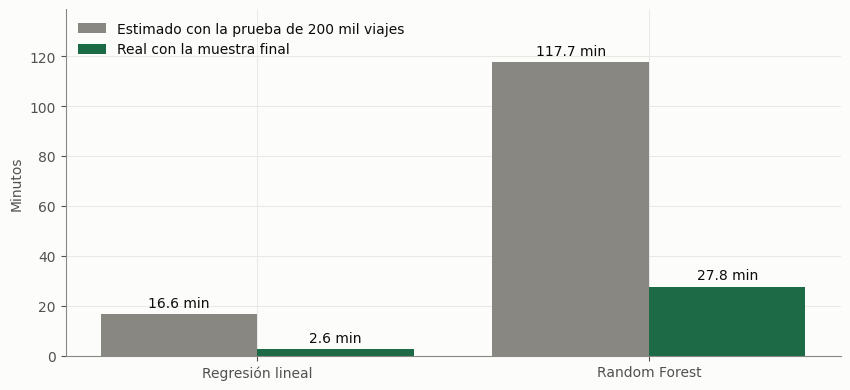

In [ ]:
# Figura 14, minutos de entrenamiento que estimó la prueba contra los minutos reales
names = list(train_seconds)
estimated = [test_times[name] * SAMPLE_SIZE / TEST_SIZE / 60 for name in names]
real = [train_seconds[name] / 60 for name in names]
positions = range(len(names))
figure, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar([p - 0.2 for p in positions], estimated, width=0.4, color=GRAY, label="Estimado con la prueba de 200 mil viajes")
ax.bar_label(bars, labels=[f"{value:.1f} min" for value in estimated], padding=3)
bars = ax.bar([p + 0.2 for p in positions], real, width=0.4, color=GREEN, label="Real con la muestra final")
ax.bar_label(bars, labels=[f"{value:.1f} min" for value in real], padding=3)
ax.set_xticks(list(positions))
ax.set_xticklabels(names)
ax.set_ylabel("Minutos")
ax.set_ylim(0, max(estimated + real) * 1.18)
ax.legend(frameon=False)
save_figure(figure, "results/graficas/figura_14_tiempos.png")
plt.show()

Figura 14. Minutos de entrenamiento que estimó la prueba con 200 mil viajes y minutos reales con la muestra final de cada modelo.

La prueba estimó 17 minutos para la regresión lineal y 118 para el Random Forest pero tardaron 2.6 y 27.8 minutos, la estimación supone que el tiempo crece en proporción al número de viajes y eso no se cumple porque con 200 mil viajes la mayor parte del tiempo es preparación fija como crear las tareas de Spark y recorrer las etapas del pipeline, con 10 millones esa preparación se reparte entre muchos más datos. La regresión lineal fue 12 veces más rápida que el Random Forest porque ajusta un solo conjunto de pesos mientras que el Random Forest construye 20 árboles de profundidad 10.

## Evaluación

Los modelos se evalúan con RegressionEvaluator sobre el 20% de la muestra que no se usó para entrenar con tres métricas que son el RMSE, el MAE y el R².

El MAE es el error absoluto medio y dice por cuántos minutos se equivoca el modelo en promedio, el RMSE es la raíz del error cuadrático medio y castiga más los errores grandes porque eleva cada error al cuadrado antes de promediarlos y el R² dice qué parte de la variación de la duración explica el modelo, un R² de 1 es una predicción perfecta y uno de 0 es igual que predecir siempre el promedio.

In [ ]:
def evaluate(predictions):
    ''' Calcula el RMSE, el MAE y el R² de un DataFrame con predicciones '''

    return {
        metric: RegressionEvaluator(labelCol=LABEL, predictionCol="prediction", metricName=metric).evaluate(predictions)
        for metric in ["rmse", "mae", "r2"]
    }

In [ ]:
# Métricas de cada modelo con el set de evaluación
rows = []
for name, model in models.items():
    predictions = model.transform(test_part).cache()
    metrics = evaluate(predictions)
    predictions.unpersist()
    rows.append({
        "modelo": name,
        "viajes_entrenamiento": train_rows,
        "viajes_evaluacion": test_rows,
        "rmse": round(metrics["rmse"], 3),
        "mae": round(metrics["mae"], 3),
        "r2": round(metrics["r2"], 4),
        "minutos_entrenamiento": round(train_seconds[name] / 60, 1),
    })
model_metrics = pd.DataFrame(rows)
save_table(model_metrics, "results/metricas/metricas_modelos.csv")

# El mejor modelo es el de menor RMSE
best_name = model_metrics.sort_values("rmse").iloc[0]["modelo"]
print("Mejor modelo:", best_name)
model_metrics

Guardado results/metricas/metricas_modelos.csv con 2 filas
Mejor modelo: Random Forest


,modelo,viajes_entrenamiento,viajes_evaluacion,rmse,mae,r2,minutos_entrenamiento
0,Regresión lineal,8002656,2000445,6.656,4.169,0.5722,2.6
1,Random Forest,8002656,2000445,6.497,4.043,0.5923,27.8


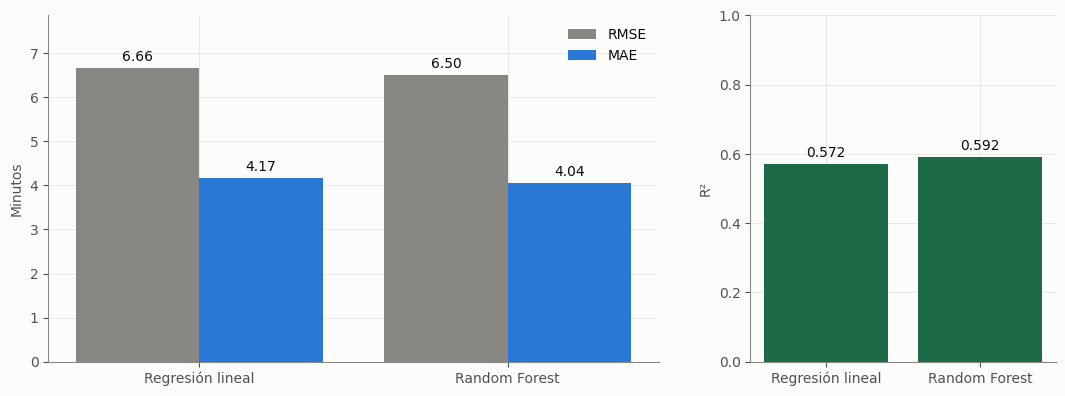

In [ ]:
# Figura 15, RMSE y MAE en minutos y R² de los dos modelos con el set de evaluación
figure, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
positions = range(len(model_metrics))
for offset, metric, color in [(-0.2, "rmse", GRAY), (0.2, "mae", BLUE)]:
    bars = ax1.bar([p + offset for p in positions], model_metrics[metric], width=0.4, color=color, label=metric.upper())
    ax1.bar_label(bars, labels=[f"{value:.2f}" for value in model_metrics[metric]], padding=3)
ax1.set_xticks(list(positions))
ax1.set_xticklabels(model_metrics["modelo"])
ax1.set_ylabel("Minutos")
ax1.set_ylim(0, model_metrics["rmse"].max() * 1.18)
ax1.legend(frameon=False)
bars = ax2.bar(model_metrics["modelo"], model_metrics["r2"], color=GREEN)
ax2.bar_label(bars, labels=[f"{value:.3f}" for value in model_metrics["r2"]], padding=3)
ax2.set_ylabel("R²")
ax2.set_ylim(0, 1)
save_figure(figure, "results/graficas/figura_15_metricas.png")
plt.show()

Figura 15. RMSE y MAE en minutos y R² de los dos modelos con el 20% de la muestra que no se usó para entrenar.

El Random Forest tuvo el menor error con un RMSE de 6.50 minutos, un MAE de 4.04 minutos y un R² de 0.592 contra un RMSE de 6.66, un MAE de 4.17 y un R² de 0.572 de la regresión lineal, la mejora es pequeña y el Random Forest tardó 11 veces más en entrenar, esto indica que la relación entre las variables y la duración es casi lineal y que una relación entre la distancia y la duración como la que aprende la regresión lineal ya explica la mayor parte de lo que se puede explicar con estas variables.

Un R² de 0.59 quiere decir que el modelo explica el 59% de la variación de la duración y el resto depende de datos que no están en los registros como el ritmo de cada usuario, las paradas durante el viaje, la ruta que siguió o si la bicicleta era eléctrica.

En los dos modelos el RMSE es mayor que el MAE por unos 2.5 minutos, esto indica que la mayoría de los errores son pequeños pero hay algunos viajes con errores grandes que suben el RMSE porque cada error se eleva al cuadrado, más adelante en la Figura 19 se mide en qué viajes están esos errores grandes.

Para entender por qué el Random Forest mejoró poco se revisa la importancia de cada variable, MLlib calcula cuánto ayuda cada variable a reducir el error en las divisiones de los 20 árboles y normaliza los valores para que todas sumen 1.

Guardado results/metricas/importancia_variables.csv con 11 filas


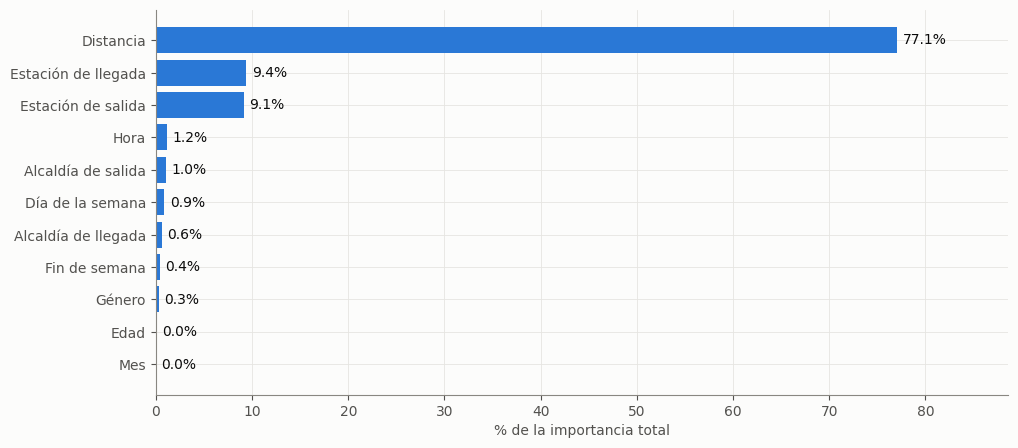

In [ ]:
# Importancia de cada variable en el Random Forest, el vector sigue el orden en que VectorAssembler unió las columnas
forest = models["Random Forest"].stages[-1]
spanish = {
    "distance_km": "Distancia", "age": "Edad", "is_weekend": "Fin de semana", "pickup_station": "Estación de salida",
    "dropoff_station": "Estación de llegada", "hour": "Hora", "day_of_week": "Día de la semana", "month": "Mes",
    "gender": "Género", "pickup_alcaldia": "Alcaldía de salida", "dropoff_alcaldia": "Alcaldía de llegada",
}
importance = pd.DataFrame({
    "variable": [spanish[column] for column in NUMERIC_RF + CATEGORICAL_RF],
    "importancia": forest.featureImportances.toArray(),
}).sort_values("importancia")
save_table(importance.sort_values("importancia", ascending=False), "results/metricas/importancia_variables.csv")

# Figura 16, importancia de cada variable como porcentaje del total
figure, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(importance["variable"], importance["importancia"] * 100, color=BLUE)
ax.bar_label(bars, labels=[f"{value * 100:.1f}%" for value in importance["importancia"]], padding=4)
ax.set_xlabel("% de la importancia total")
ax.set_xlim(0, importance["importancia"].max() * 100 * 1.15)
save_figure(figure, "results/graficas/figura_16_importancia.png")
plt.show()

Figura 16. Importancia de cada variable en el Random Forest como porcentaje del total.

La distancia tiene el 77.1% de la importancia total, después siguen la estación de llegada con 9.4% y la estación de salida con 9.1% y entre las tres suman el 95.6%, la hora tiene solo 1.2% y el día de la semana 0.9% mientras que la edad y el mes tienen 0.0%, es decir que los árboles casi nunca las usaron para dividir los viajes.

Esto explica por qué el Random Forest mejoró poco sobre la regresión lineal, la mayor parte de lo que se puede predecir depende de la distancia y esa relación es casi lineal como se vio en la Figura 13.

Las estaciones aportan algo más porque salir o llegar a ciertas estaciones toma más tiempo probablemente por sus calles, sus semáforos o el tráfico de la zona y la edad y el género casi no ayudan porque la duración depende más del recorrido que de quién lo hace por eso se podrían quitar del modelo sin perder precisión y el modelo sería más simple.

## Predicciones con enero de 2026

El mejor modelo se usa para predecir la duración de los viajes de enero de 2026, ese mes no se usó en el entrenamiento y por eso simula usar el modelo con viajes nuevos, como estos viajes ya terminaron se conoce su duración real y se puede medir qué tan bien predice el modelo fuera de los datos con los que se entrenó.

In [ ]:
# Predicciones del mejor modelo para todos los viajes limpios de enero de 2026
start = time.time()
january = models[best_name].transform(predict).withColumn("error_min", F.col("prediction") - F.col(LABEL)).cache()
january_metrics = evaluate(january)
january_rows = january.count()
print(f"{best_name} con {january_rows:,} viajes de {PREDICT_MONTH} en {time.time() - start:.0f} s")
print(f"RMSE {january_metrics['rmse']:.2f}, MAE {january_metrics['mae']:.2f}, R² {january_metrics['r2']:.3f}")

# Se guardan las métricas de enero de 2026 aparte de las del set de evaluación
january_table = pd.DataFrame([{
    "modelo": best_name,
    "mes": PREDICT_MONTH,
    "viajes": january_rows,
    "rmse": round(january_metrics["rmse"], 3),
    "mae": round(january_metrics["mae"], 3),
    "r2": round(january_metrics["r2"], 4),
}])
save_table(january_table, "results/metricas/metricas_enero_2026.csv")

Random Forest con 1,463,259 viajes de 2026-01 en 116 s
RMSE 6.52, MAE 3.99, R² 0.597
Guardado results/metricas/metricas_enero_2026.csv con 1 filas


En enero de 2026 el Random Forest tuvo un RMSE de 6.52 minutos, un MAE de 3.99 minutos y un R² de 0.597, los resultados son iguales a los del set de evaluación y esto indica que el modelo no se ajustó solo a los viajes de 2024 y 2025 y que funciona con viajes que no vio durante el entrenamiento.

In [ ]:
# Diez viajes al azar con su duración real y la predicha en minutos
(
    january.select(
        "pickup",
        "pickup_colonia",
        "dropoff_colonia",
        F.round("distance_km", 2).alias("km"),
        F.round(LABEL, 1).alias("real"),
        F.round("prediction", 1).alias("predicha"),
    )
    .orderBy(F.rand(SEED))
    .limit(10)
    .toPandas()
)

,pickup,pickup_colonia,dropoff_colonia,km,real,predicha
0,2026-01-25 09:39:46,Roma Sur,San Miguel Chapultepec,2.25,10.9,19.8
1,2026-01-14 17:51:47,Anahuac,San Rafael,1.85,24.3,13.8
2,2026-01-27 08:45:23,Tacuba,San Rafael,3.75,19.8,22.4
3,2026-01-17 14:13:38,Sector Naval,Claveria,1.01,6.2,9.5
4,2026-01-10 17:20:00,Independencia,Portales Norte,1.00,13.1,9.8
5,2026-01-05 08:52:38,San Simon Ticumac,Roma Norte,5.25,27.5,30.2
6,2026-01-13 16:16:13,Obrera,Algarin,0.45,4.9,6.0
7,2026-01-26 06:48:14,Algarin,Roma Norte,2.17,12.1,14.0
8,2026-01-28 09:31:57,Claveria,Irrigacion,3.58,24.7,21.7
9,2026-01-13 08:30:40,Escandon,San Pedro de los Pinos,0.88,8.2,7.8


La tabla del error se agrupa por hora y alcaldía de salida y también guarda totales, en Tableau el error promedio se calcula dividiendo el error absoluto total entre los viajes y así se puede ver en qué horas y en qué alcaldías se equivoca más el modelo.

In [ ]:
# Error del modelo por hora y alcaldía de salida
error_table = (
    january.groupBy(F.col("hour").alias("hora"), F.col("pickup_alcaldia").alias("alcaldia_salida"))
    .agg(
        F.count("*").alias("viajes"),
        F.round(F.sum(LABEL), 2).alias("minutos_reales_totales"),
        F.round(F.sum("prediction"), 2).alias("minutos_predichos_totales"),
        F.round(F.sum(F.abs("error_min")), 2).alias("error_absoluto_total"),
    )
    .orderBy("hora", "alcaldia_salida")
    .toPandas()
)
save_table(error_table, "tableau/datos/error_modelo.csv")

# Error absoluto promedio por hora con todas las alcaldías
by_hour_error = error_table.groupby("hora")[["error_absoluto_total", "viajes"]].sum()
(by_hour_error["error_absoluto_total"] / by_hour_error["viajes"]).round(2).rename("mae_minutos")

Guardado tableau/datos/error_modelo.csv con 120 filas


,mae_minutos
hora,
0,5.86
5,2.95
6,2.70
7,2.83
8,3.07
9,3.54
10,4.50
11,4.82
12,4.92


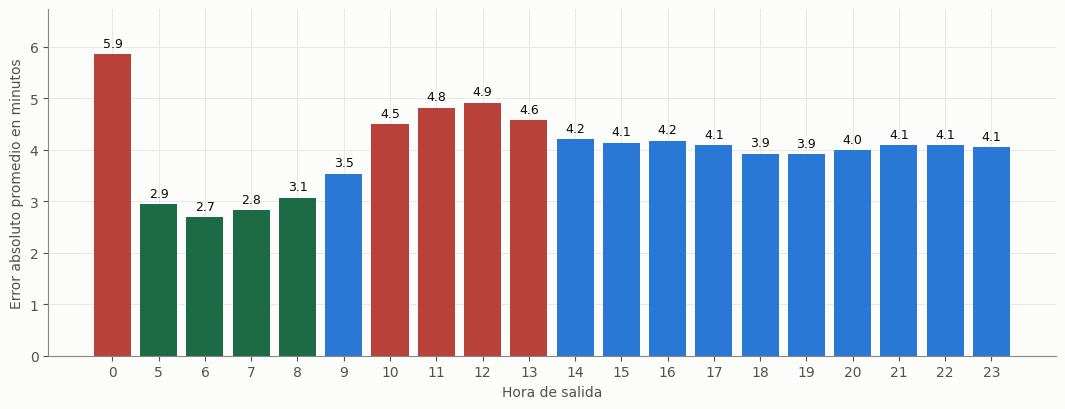

In [ ]:
# Figura 17, error absoluto promedio por hora de salida en enero de 2026
mae_hour = (by_hour_error["error_absoluto_total"] / by_hour_error["viajes"])
colors = [GREEN if value <= 3.1 else RED if value >= 4.5 else BLUE for value in mae_hour]
figure, ax = plt.subplots(figsize=(13, 4.5))
bars = ax.bar([str(hour) for hour in mae_hour.index], mae_hour, color=colors)
ax.bar_label(bars, labels=[f"{value:.1f}" for value in mae_hour], padding=3, fontsize=9)
ax.set_xlabel("Hora de salida")
ax.set_ylabel("Error absoluto promedio en minutos")
ax.set_ylim(0, mae_hour.max() * 1.15)
save_figure(figure, "results/graficas/figura_17_error_por_hora.png")
plt.show()

Figura 17. Error absoluto promedio en minutos por hora de salida en enero de 2026, en verde las horas con menos error y en rojo las de más error.

El modelo se equivoca menos entre las 5 y las 8 de la mañana con un error de 2.7 a 3.1 minutos y más entre las 10 y las 13 horas con un error de 4.5 a 4.9 minutos, en las mañanas la mayoría de los viajes son traslados directos al trabajo o la escuela y al mediodía hay más viajes con paradas o paseos que duran más de lo que indica su distancia.

La hora 0 tiene el error más alto con 5.86 minutos porque tiene pocos viajes antes del cierre del sistema y de la 1 a las 4 de la mañana no hay viajes.

Al comparar con la Figura 11 se ve que el modelo es más preciso justo en el inicio de la hora pico de la mañana cuando la mayoría de los viajes son traslados directos, para el operador esto es útil porque en las horas pico es cuando más necesita saber cuándo va a llegar una bicicleta a cada estación, a mediodía el error sube porque hay más viajes con paradas y paseos que duran más de lo que indica su distancia y el modelo no tiene un dato que le diga cuál viaje es un paseo.

In [ ]:
# Muestra de mil predicciones para el repositorio
sample_predictions = (
    january.select(
        F.col("pickup").alias("salida"),
        F.col("pickup_station").alias("estacion_salida"),
        F.col("dropoff_station").alias("estacion_llegada"),
        F.round("distance_km", 2).alias("km"),
        F.round(LABEL, 2).alias("minutos_reales"),
        F.round("prediction", 2).alias("minutos_predichos"),
        F.round("error_min", 2).alias("error_minutos"),
    )
    .orderBy(F.rand(SEED))
    .limit(1000)
    .toPandas()
)
save_table(sample_predictions, "results/predicciones/predicciones_enero_2026.csv")

Guardado results/predicciones/predicciones_enero_2026.csv con 1,000 filas


Para la Figura 18 se toman 10 mil viajes de enero de 2026 al azar porque con todos los viajes del mes los puntos se encimarían.

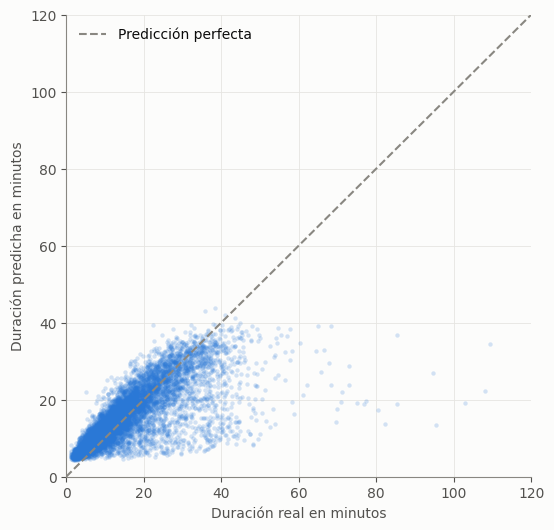

In [ ]:
# Duración real contra predicha de 10 mil viajes al azar
points = january.select(LABEL, "prediction").orderBy(F.rand(SEED)).limit(10_000).toPandas()

figure, ax = plt.subplots(figsize=(6, 6))
ax.scatter(points[LABEL], points["prediction"], s=10, alpha=0.2, color=BLUE, linewidths=0)
ax.plot([0, MAX_MINUTES], [0, MAX_MINUTES], color=GRAY, linewidth=1.5, linestyle="--", label="Predicción perfecta")
ax.set_xlim(0, MAX_MINUTES)
ax.set_ylim(0, MAX_MINUTES)
ax.set_xlabel("Duración real en minutos")
ax.set_ylabel("Duración predicha en minutos")
ax.legend(frameon=False)
save_figure(figure, "results/graficas/figura_18_real_contra_predicha.png")
plt.show()

Figura 18. Duración real contra duración predicha de 10 mil viajes de enero de 2026 elegidos al azar, la línea punteada es la predicción perfecta.

Cada punto es un viaje, si el modelo fuera perfecto todos los puntos estarían sobre la línea punteada y entre más lejos están de la línea más grande es el error.

La mayoría de los puntos están cerca de la línea en los viajes de menos de 30 minutos, en los viajes más largos el modelo predice casi siempre menos de 40 minutos aunque el viaje real haya durado mucho más esto pasa porque los viajes largos son pocos en los datos y su duración depende más de las paradas y del ritmo del usuario que de la distancia.

Para medir con números lo que se ve en la Figura 18 los viajes de enero de 2026 se agrupan por su duración real y en cada rango se compara la duración real promedio con la predicha.

Guardado results/metricas/error_por_duracion.csv con 6 filas


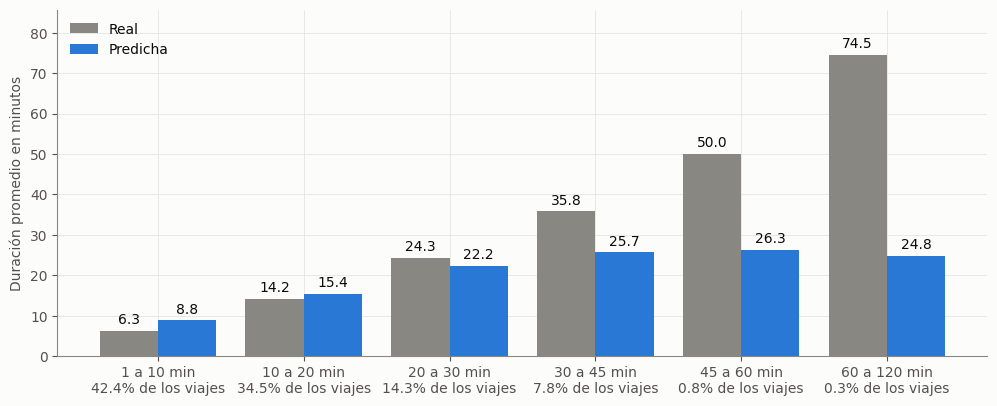

,rango,viajes,real,predicha,mae,porcentaje
0,1 a 10,619930,6.31,8.82,2.65,42.4
1,10 a 20,504256,14.24,15.42,3.03,34.5
2,20 a 30,208702,24.31,22.25,4.74,14.3
3,30 a 45,114461,35.80,25.67,10.53,7.8
4,45 a 60,11878,49.98,26.28,23.70,0.8
5,60 a 120,4032,74.53,24.85,49.68,0.3


In [ ]:
# Duración real y predicha promedio y error absoluto por rango de duración real
duration_range = (
    F.when(F.col(LABEL) < 10, "1 a 10")
    .when(F.col(LABEL) < 20, "10 a 20")
    .when(F.col(LABEL) < 30, "20 a 30")
    .when(F.col(LABEL) < 45, "30 a 45")
    .when(F.col(LABEL) < 60, "45 a 60")
    .otherwise("60 a 120")
)
order = ["1 a 10", "10 a 20", "20 a 30", "30 a 45", "45 a 60", "60 a 120"]
by_duration = (
    january.groupBy(duration_range.alias("rango"))
    .agg(
        F.count("*").alias("viajes"),
        F.avg(LABEL).alias("real"),
        F.avg("prediction").alias("predicha"),
        F.avg(F.abs("error_min")).alias("mae"),
    )
    .toPandas()
    .set_index("rango")
    .loc[order]
    .reset_index()
)
by_duration["porcentaje"] = (by_duration["viajes"] / by_duration["viajes"].sum() * 100).round(1)
save_table(by_duration.round(2), "results/metricas/error_por_duracion.csv")

# Figura 19, duración real y predicha promedio por rango con el porcentaje de viajes de cada rango
positions = range(len(by_duration))
figure, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar([p - 0.2 for p in positions], by_duration["real"], width=0.4, color=GRAY, label="Real")
ax.bar_label(bars, labels=[f"{value:.1f}" for value in by_duration["real"]], padding=3)
bars = ax.bar([p + 0.2 for p in positions], by_duration["predicha"], width=0.4, color=BLUE, label="Predicha")
ax.bar_label(bars, labels=[f"{value:.1f}" for value in by_duration["predicha"]], padding=3)
ax.set_xticks(list(positions))
ax.set_xticklabels([f"{name} min\n{percent}% de los viajes" for name, percent in zip(by_duration["rango"], by_duration["porcentaje"])])
ax.set_ylabel("Duración promedio en minutos")
ax.set_ylim(0, by_duration["real"].max() * 1.15)
ax.legend(frameon=False)
save_figure(figure, "results/graficas/figura_19_error_por_duracion.png")
plt.show()
by_duration.round(2)

Figura 19. Duración real y predicha promedio en minutos por rango de duración real en enero de 2026, debajo de cada rango está el porcentaje de viajes que tiene.

En la figura 19 se observa que el modelo predice de más en los viajes cortos y de menos en los largos, en los viajes de 1 a 10 minutos que son el 42.4% predice en promedio 8.8 minutos cuando duraron 6.3 y en los de 10 a 20 minutos que son el 34.5% predice 15.4 cuando duraron 14.2, en estos dos rangos que juntos son el 76.9% de los viajes el error absoluto promedio es de 2.7 y 3 minutos.

A partir de los 30 minutos la predicción se queda entre 25 y 26 minutos sin importar cuánto dure el viaje, en los viajes de 30 a 45 minutos el error es de 10.5 minutos, en los de 45 a 60 es de 23.7 y en los de 60 a 120 es de 46.7, estos viajes son solo el 8.9% del mes y el modelo no los distingue porque su distancia se parece a la de los viajes normales y lo que los hace largos son las paradas o los paseos que no están en los datos, estos errores grandes son los que hacen que el RMSE sea mayor que el MAE como se vio en la Figura 15.

Cuando el modelo no tiene datos que le digan si un viaje va a ser largo su predicción se acerca al promedio, por eso sube los viajes cortos y baja los largos, para el operador esto significa que la predicción es confiable para la mayoría de los viajes pero no srive para detectar los viajes que van a durar más de 30 minutos.

## Exportar los resultados

Las salidas se comprimen en un zip que tiene la misma estructura de carpetas del repositorio, el zip se descarga desde Colab y también queda una copia en la carpeta de respaldo en Drive.

Estos son los archivos y lo que guarda cada uno.

| Archivo | Contenido |
|---|---|
| tableau/datos/demanda.csv | Viajes, minutos y kilómetros por fecha, hora y alcaldía de salida |
| tableau/datos/estaciones.csv | Viajes y minutos por año, mes y estación de salida con su ubicación |
| tableau/datos/usuarios.csv | Viajes y minutos por año, mes, género y grupo de edad |
| tableau/datos/error_modelo.csv | Error del mejor modelo en enero de 2026 por hora y alcaldía |
| results/metricas/metricas_modelos.csv | RMSE, MAE, R² y tiempo de entrenamiento de los dos modelos |
| results/metricas/metricas_enero_2026.csv | Métricas del mejor modelo con los viajes de enero de 2026 |
| results/predicciones/predicciones_enero_2026.csv | Mil viajes de enero de 2026 con su duración real y la predicha |
| results/graficas/ | Las 19 figuras del notebook en PNG, el nombre de cada archivo empieza con el número de su figura |
| results/metricas/importancia_variables.csv | Importancia de cada variable en el Random Forest |
| results/metricas/error_por_duracion.csv | Duración real, predicha y error por rango de duración en enero de 2026 |

In [ ]:
# Se comprime la carpeta de salidas, se respalda en Drive y se descarga
from google.colab import files
zip_path = Path(shutil.make_archive("/content/salidas", "zip", OUTPUT_DIR))
backup(zip_path)
print(f"{zip_path.name}: {zip_path.stat().st_size / 1024**2:.1f} MB")
files.download(str(zip_path))

salidas.zip: 2.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tablero en Tableau Public

El tablero se construyó en Tableau Public con las cuatro tablas que se exportaron del análisis y del modelo y está pensado para el operador del sistema que decide dónde y cuándo poner bicicletas y para cualquier persona que quiera entender cómo se usa Ecobici sin conocer los datos.

Tiene tres dashboards con filtros de año, mes, día de la semana y alcaldía y una nota debajo de cada gráfica que explica cómo leerla.

Enlace: [Ver en Tableau Public](https://public.tableau.com/app/profile/oswaldo.hernandez2651/viz/ecobici_duration_visualization/Dashboard2)

### Uso de Ecobici

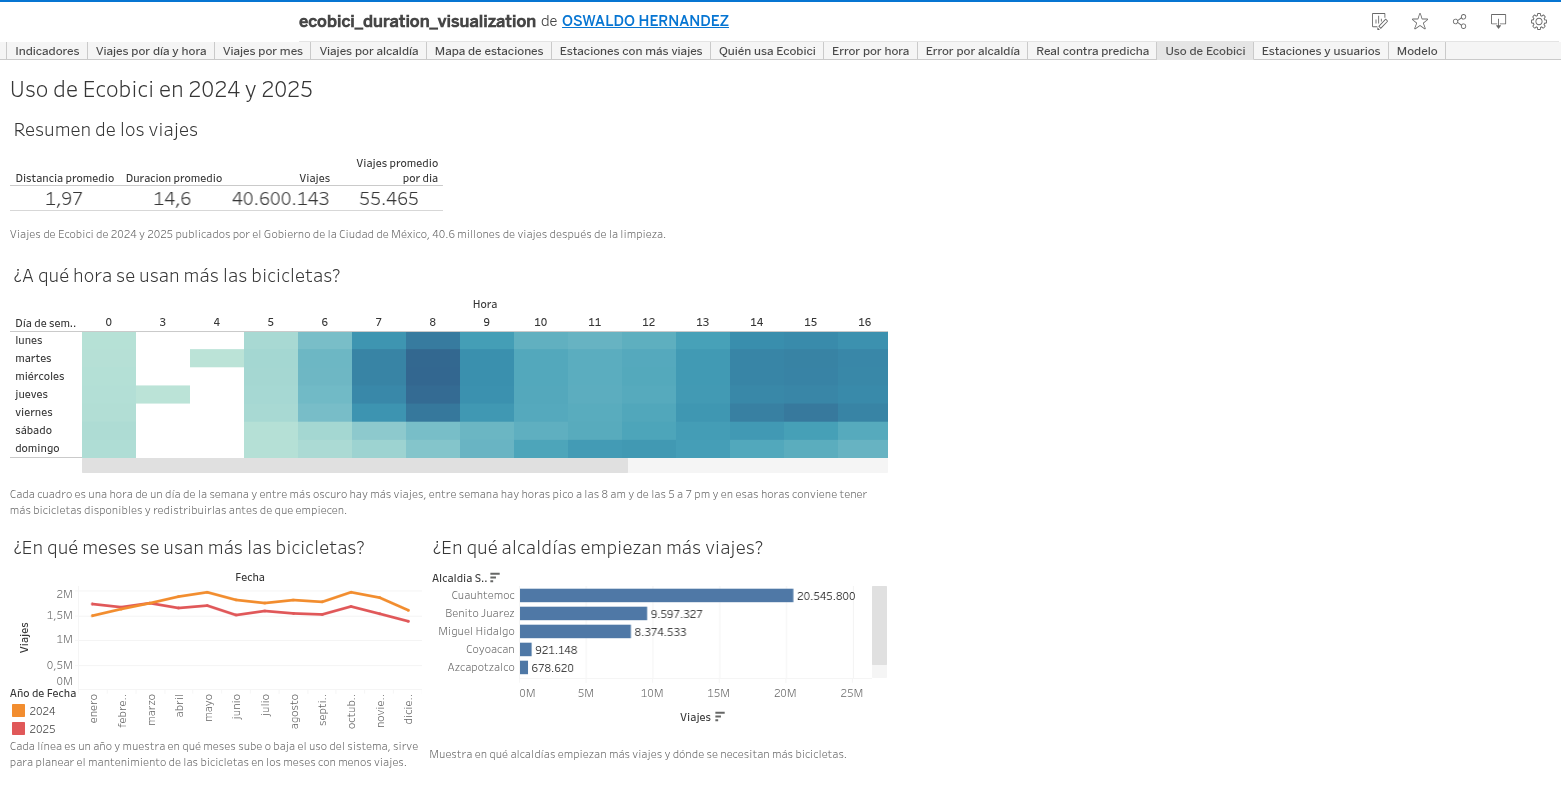

Figura 20. Dashboard Uso de Ecobici en Tableau Public.

Este dashboard resume los 40.6 millones de viajes de 2024 y 2025 y sus indicadores coinciden con los del notebook, un viaje dura en promedio 14.6 minutos, recorre 1.97 km y hay 55,465 viajes al día.

El mapa de calor muestra las horas pico de las 8 de la mañana y de las 17 a las 19 horas entre semana, con esta información el operador puede decidir a qué horas redistribuir las bicicletas para que las estaciones no se queden vacías.

La gráfica por mes muestra en qué meses baja el uso del sistema y sirve para planear el mantenimiento de las bicicletas en esos meses, la gráfica por alcaldía muestra que en Cuauhtémoc empiezan 20.5 millones de viajes que son la mitad de todo el sistema.

### Estaciones y usuarios

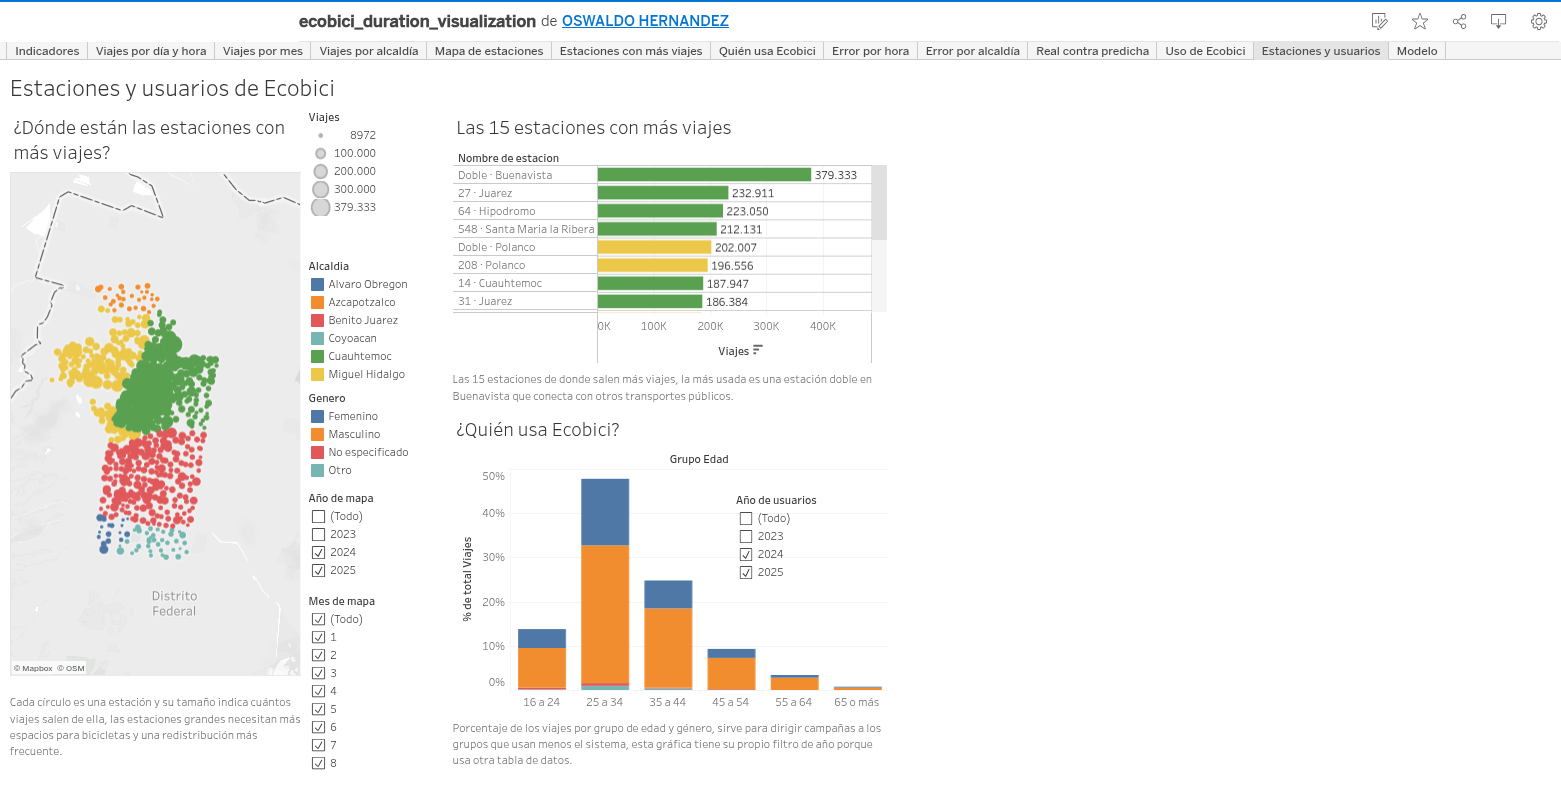

Figura 21. Dashboard Estaciones y usuarios en Tableau Public.

El mapa muestra cada estación con un círculo cuyo tamaño indica cuántos viajes salen de ella, las estaciones con más viajes están en el centro de la ciudad en las alcaldías Cuauhtémoc y Miguel Hidalgo y esas estaciones necesitan más espacios para bicicletas y una redistribución más frecuente.

El ranking muestra las 15 estaciones con más viajes y la más usada es una estación doble en Buenavista con 379,333 viajes, en Tableau la columna de la estación se leyó como número y las estaciones dobles como 271-272 quedaron vacías es por eso que en el tablero se identifican con la palabra Doble, su colonia y su ubicación, en Buenavista hay cinco estaciones dobles y en Polanco dos.

La gráfica de usuarios muestra que el grupo de 25 a 34 años hace casi la mitad de los viajes y que la mayoría de los viajes los hacen hombres, sirve para dirigir campañas a los grupos que usan menos el sistema como las mujeres y las personas mayores de 55 años.

### Modelo

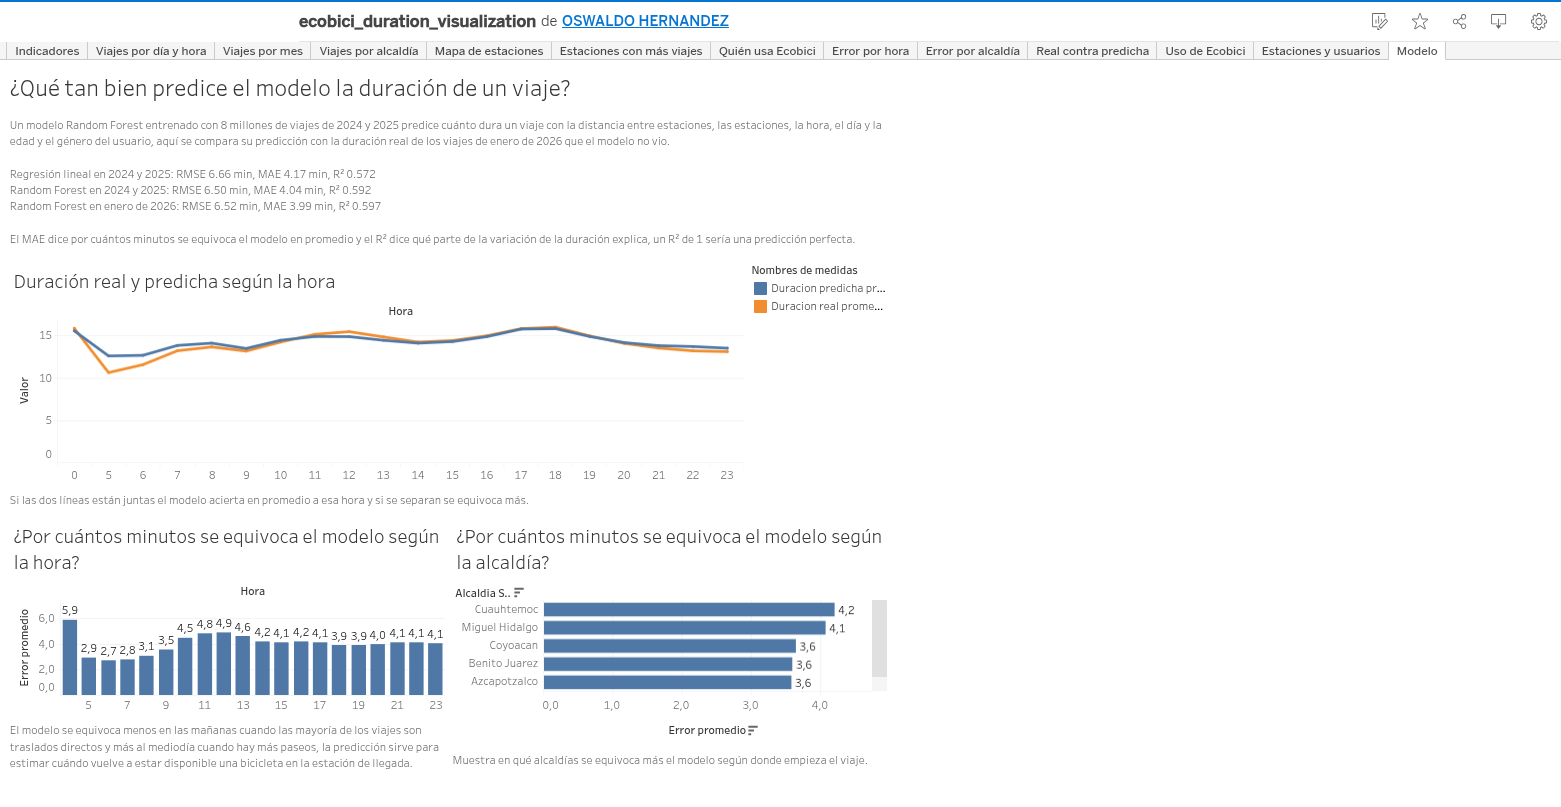

Figura 22. Dashboard Modelo en Tableau Public.

Este dashboard compara la duración real de los viajes de enero de 2026 con la que predijo el Random Forest, las dos líneas están juntas en casi todas las horas y se separan en las primeras horas de la mañana donde el modelo predice viajes un poco más largos de lo que fueron.

El error promedio es menor entre las 5 y las 8 de la mañana y mayor al mediodía y por alcaldía va de 3.6 minutos en Azcapotzalco, Benito Juárez y Coyoacán a 4.2 minutos en Cuauhtémoc.

Con la predicción de la duración el operador puede estimar cuándo va a llegar una bicicleta a la estación de destino y saber con anticipación cuántas bicicletas tendrá disponibles en cada estación.

## Conclusiones

PySpark permitió procesar en una máquina con 2 núcleos y 12.7 GB de RAM un volumen de datos que no cabría completo en su memoria, las decisiones que más ayudaron fueron convertir los CSV a Parquet una sola vez, contar las reglas de limpieza en una sola pasada y mandar el catálogo de estaciones completo a cada tarea con broadcast, el plan físico confirmó que Spark aplica los filtros antes de las uniones y solo lee las columnas y los meses que necesita.

Revisar el esquema antes de unir los archivos evitó errores que no se habrían notado a simple vista como la columna de la fecha de llegada que cambia de nombre entre meses y los archivos que agrupan los viajes por la fecha de llegada, la limpieza quitó el 4.19% de los viajes y la mayoría fueron viajes redondos y velocidades imposibles.

El Random Forest predijo la duración con un error promedio de 4 minutos y mantuvo sus resultados con los viajes de enero de 2026, la mejora sobre la regresión lineal fue pequeña porque con los datos disponibles la duración depende sobre todo de la distancia y el 41% de la variación que no explica el modelo depende del ritmo del usuario, las paradas y la ruta que no están en los registros, por eso el modelo subestima los viajes de más de 30 minutos y se equivoca más al mediodía cuando hay más paseos.

El tablero muestra que Ecobici se usa sobre todo para ir al trabajo y la escuela con horas pico a las 8 de la mañana y de las 17 a las 19 horas entre semana y que la mitad de los viajes empiezan en la alcaldía Cuauhtémoc, con esta información el operador puede decidir a qué horas y en qué estaciones redistribuir las bicicletas.

# Link de este archivo en el repositorio
[ecobici_duration_pyspark.ipynb]()

## Referencias

Apache Software Foundation. (s.f.-a). *MLlib: Main guide*. Recuperado el 6 de noviembre de 2026, de https://spark.apache.org/docs/3.5.5/ml-guide.html

Apache Software Foundation. (s.f.-b). *Spark 3.5.5 documentation*. Recuperado el 6 de noviembre de 2026, de https://spark.apache.org/docs/3.5.5/

Chilango. (2024, 2 de septiembre). *¿Cuánto tiempo se puede usar la Ecobici? Horarios y precios*. https://www.chilango.com/noticias/transporte/cuanto-tiempo-se-puede-usar-la-ecobici-horarios-precios/

Expansión. (2025a, 5 de septiembre). *Cicloestación Buenavista es la más usada de todo el sistema Ecobici en CDMX*. https://politica.expansion.mx/cdmx/2025/09/05/cicloestacion-buenavista-es-la-mas-usada-de-todo-el-sistema-ecobici-en-cdmx

Expansión. (2025b, 8 de enero). *El sistema Ecobici rompe récord en 2024, alcanza más de 22 millones de viajes*. https://politica.expansion.mx/cdmx/2025/01/08/el-sistema-ecobici-rompe-record-en-2024-alcanza-mas-de-22-millones-de-viajes

Gobierno de la Ciudad de México. (s.f.). *Datos abiertos ECOBICI* [Conjunto de datos]. Recuperado el 6 de noviembre de 2026, de https://ecobici.cdmx.gob.mx/datos-abiertos/

Hernández Santes, O. I. (2026). *ecobici_duration_visualization* [Tablero]. Tableau Public. https://public.tableau.com/app/profile/oswaldo.hernandez2651/viz/ecobici_duration_visualization/Dashboard2

Portal de Datos Abiertos de la Ciudad de México. (s.f.). *Cicloestaciones Ecobici (nuevo sistema)* [Conjunto de datos]. Recuperado el 6 de noviembre de 2026, de https://datos.cdmx.gob.mx/dataset/cicloestaciones-ecobici-nuevo-sistema